<a href="https://colab.research.google.com/github/Trinaldi3/Probabilitas-dan-Statistika/blob/main/EksplorasiPythonUntukProbabilitasdanDistribusiProbabilitas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Eksplorasi Python untuk Probabilitas dan Distribusi Probabilitas
**Mata Kuliah:** Probabilitas dan Statistika  |  **Studi kasus:** Teknik Informatika

**Nama / NIM:** [Tri Naldi Syaputra Siregar / 2455301238]  

Notebook ini berisi 24 kasus: 7 permasalahan probabilitas (P1-P7), 7 distribusi diskrit (D1-D7), 8 distribusi kontinu (K1-K8), dan 2 studi kasus terpadu perencanaan kapasitas (T1-T2). Setiap kasus berisi skenario, konsep, kode, output, dan interpretasi.

## Daftar library Python yang digunakan

| Library | Fungsi utama | Contoh penggunaan | Dipakai pada |
|---|---|---|---|
| `numpy` | array, pembangkit acak, aljabar linear | `rng.binomial(20, 0.08, size=300_000)` | P1–P7, D1–D7, K1–K8, T1–T2 |
| `scipy.stats` | distribusi (pmf, pdf, cdf, sf, ppf, rvs, fit) dan uji hipotesis | `stats.binom.cdf(2, 20, 0.08)` | P4, P6, D1–D7, K1–K8, T1 |
| `scipy.special` | fungsi khusus (`gammaln`, `gamma`) | `special.gammaln(N + 1)` | P1, K5 |
| `scipy.integrate` | integral numerik (`quad`) | `integrate.quad(lambda t: t * U.pdf(t), 0, 50)[0]` | K1, K4, K7 |
| `pandas` | tabel data (`DataFrame`, `value_counts`) | `pd.DataFrame({"eigen": pi_eig, "linear": pi_lin}, index=halaman)` | P1, P3–P6, K6, T2, rekap |
| `matplotlib.pyplot` | visualisasi PMF, PDF, CDF, histogram | `ax.bar(x, pmf_manual)` | seluruh kasus |
| `sympy` | aritmetika pecahan eksak (`Rational`) | `sp.Rational(95, 100) * sp.Rational(2, 100)` | P2, P7 |
| `networkx` | graf berarah dan PageRank | `nx.pagerank(G, alpha=0.85, weight="weight")` | P5 |
| `scikit-learn` | `CountVectorizer`, `MultinomialNB` | `MultinomialNB(alpha=1).fit(X, data.label)` | P3 |
| `math` | `comb`, `factorial`, `exp`, `log`, `erfc` | `math.comb(20, 2)` | P6, D1, D3–D7, K2–K5, T1–T2 |
| `itertools` | enumerasi (`product`, `combinations`) | `itertools.product([0, 1], repeat=6)` | P4, P7 |
| `heapq` | antrian prioritas (min-heap) | `heapq.heapreplace(bebas, mulai + layan[i])` | T2 |
| `hashlib` | fungsi hash `md5` | `hashlib.md5(kunci.encode()).hexdigest()` | D7 |
| `warnings` | menyembunyikan peringatan numerik | `warnings.simplefilter("ignore")` | K6 |

In [1]:
import math, itertools, heapq, hashlib, warnings

import numpy as np
import pandas as pd
import sympy as sp
import networkx as nx
import matplotlib.pyplot as plt
from scipy import stats, special, integrate
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

rng = np.random.default_rng(2026)           # seed tetap supaya hasil bisa diulang
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "font.family": "serif",
                     "font.serif": ["Times New Roman", "Liberation Serif",
                                    "DejaVu Serif"]})

def titik(n):                                # 1000000 -> "1.000.000"
    return f"{n:,}".replace(",", ".")

def se_prop(p, n):
    """Galat baku Monte Carlo untuk proporsi dari n pengulangan independen."""
    return math.sqrt(p * (1 - p) / n)

def se_batch(indikator, batch=30):
    """Galat baku untuk data berkorelasi (rantai Markov, antrian): batch means."""
    x = np.asarray(indikator, dtype=float)
    m = len(x) // batch * batch
    return x[:m].reshape(batch, -1).mean(axis=1).std(ddof=1) / np.sqrt(batch)

# Tabel rekap: tiap besaran dihitung dengan tiga cara (rumus, pustaka, simulasi)
REKAP = []
def catat(kasus, besaran, analitik, pustaka, simulasi, se=None):
    REKAP.append({"kasus": kasus, "besaran": besaran, "analitik": analitik,
                  "pustaka": pustaka, "simulasi": simulasi, "se": se})
print("Lingkungan siap. numpy", np.__version__, "| scipy", __import__("scipy").__version__)

Lingkungan siap. numpy 2.4.6 | scipy 1.16.3


# Bagian A - Permasalahan Probabilitas

## P1. Tabrakan ID acak (paradoks ulang tahun)  *(tingkat: Dasar)*

**Skenario.** Sebuah aplikasi memberi setiap pengguna baru sebuah ID acak 16-bit, jadi ada N = 65.536 nilai yang mungkin. Pertanyaannya: berapa pengguna yang sudah bisa didaftarkan sebelum ada dua orang yang kebetulan mendapat ID sama?

**Konsep.** Soal ini memakai peluang klasik dan aturan komplemen. Peluang *tidak* ada tabrakan di antara n ID adalah hasil kali (N−i)/N untuk i = 0 sampai n−1, sehingga P(tabrakan) = 1 − ∏(N−i)/N. Untuk n yang jauh lebih kecil dari N, rumus ini dapat didekati dengan 1 − exp(−n(n−1)/2N), dan peluang tabrakan mencapai 50% ketika n ≈ 1,1774√N.

Rumus eksak dihitung dua kali: lewat hasil kali langsung dan lewat fungsi *log*-gamma `scipy.special.gammaln`, lalu dibandingkan dengan simulasi 20.000 pengulangan untuk tiap nilai n.

In [2]:
N = 2**16                                   # ruang ID 16-bit: 65.536 nilai

def p_tabrakan(n, N=N):
    """Peluang ada minimal dua ID sama di antara n ID acak (rumus eksak)."""
    i = np.arange(n)
    return 1 - np.exp(np.sum(np.log1p(-i / N)))      # 1 - prod((N - i) / N)

def p_pustaka(n, N=N):
    """Cara kedua: log-gamma dari scipy.special, 1 - N!/((N-n)! N^n)."""
    return 1 - np.exp(special.gammaln(N + 1) - special.gammaln(N - n + 1) - n * np.log(N))

def p_aproks(n, N=N):
    return 1 - np.exp(-n * (n - 1) / (2 * N))

def simulasi(n, N=N, ulang=20_000):
    tabrak = 0
    for _ in range(ulang):
        tabrak += len(np.unique(rng.integers(0, N, size=n))) < n
    return tabrak / ulang

tabel = pd.DataFrame({"n": [50, 100, 200, 300, 500]})
tabel["eksak"] = [p_tabrakan(n) for n in tabel.n]
tabel["gammaln"] = [p_pustaka(n) for n in tabel.n]
tabel["aproksimasi"] = [p_aproks(n) for n in tabel.n]
tabel["simulasi"] = [simulasi(n) for n in tabel.n]
print(tabel.round(4).to_string(index=False))

n50 = next(n for n in range(2, N) if p_tabrakan(n) >= 0.5)
print("\nn minimum agar peluang tabrakan >= 50% :", n50)
print("Perkiraan 1,1774 * akar(N)             :", round(1.1774 * N**0.5, 1))
catat("P1", "P(tabrakan), n = 300", tabel.eksak[3], tabel.gammaln[3], tabel.simulasi[3],
      se_prop(tabel.eksak[3], 20_000))

  n  eksak  gammaln  aproksimasi  simulasi
 50 0.0185   0.0185       0.0185    0.0184
100 0.0728   0.0728       0.0727    0.0734
200 0.2621   0.2621       0.2619    0.2610
300 0.4961   0.4961       0.4956    0.4923
500 0.8517   0.8517       0.8510    0.8531

n minimum agar peluang tabrakan >= 50% : 302
Perkiraan 1,1774 * akar(N)             : 301.4


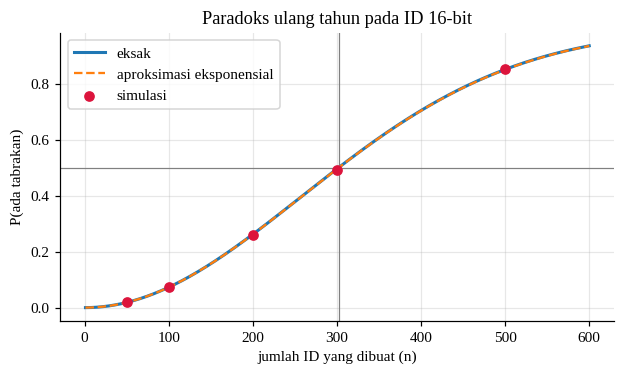

In [3]:
n_grid = np.arange(1, 601)
eksak = [p_tabrakan(n) for n in n_grid]

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(n_grid, eksak, lw=2, label="eksak")
ax.plot(n_grid, p_aproks(n_grid), "--", label="aproksimasi eksponensial")
ax.scatter(tabel.n, tabel.simulasi, color="crimson", zorder=3, label="simulasi")
ax.axhline(0.5, color="gray", lw=0.8)
ax.axvline(n50, color="gray", lw=0.8)
ax.set(xlabel="jumlah ID yang dibuat (n)", ylabel="P(ada tabrakan)",
       title="Paradoks ulang tahun pada ID 16-bit")
ax.legend()
plt.show()

**Interpretasi.** Pada n = 300 peluang tabrakan sudah 0,4961, dan nilai n terkecil yang membuat peluang itu mencapai 50% adalah 302. Angka ini hampir sama dengan perkiraan 1,1774√N = 301,4. Simulasi untuk n = 300 memberi 0,4923; selisihnya 0,0038 setara dengan sekitar satu galat baku Monte Carlo (0,0035 untuk 20.000 pengulangan), sehingga masih wajar. Dua cara hitung eksak (hasil kali dan `gammaln`) menghasilkan angka yang sama sampai empat desimal, dan aproksimasi eksponensial hanya berbeda pada desimal keempat.

Hasil ini bertentangan dengan intuisi, karena 302 pengguna hanya sekitar 0,5% dari ruang ID. Penyebabnya, yang dihitung bukan peluang seseorang bertabrakan dengan satu orang tertentu, melainkan peluang *ada* sepasang yang bertabrakan, dan jumlah pasangan pada n = 302 sudah lebih dari 45.000. Pada n = 500 peluangnya naik menjadi 0,8517.

Bagi sistem nyata, ID acak yang pendek tidak boleh dianggap unik begitu saja. Perlu ada pengecekan duplikat saat penyimpanan atau ID yang jauh lebih panjang seperti UUID 128-bit.

**Kesimpulan kasus.** Peluang tabrakan tumbuh jauh lebih cepat daripada dugaan awal; sekitar √N pengguna sudah cukup untuk membuat tabrakan sama mungkin dengan tidak.

## P2. Teorema Bayes pada detektor malware  *(tingkat: Dasar)*

**Skenario.** Sebuah antivirus menandai file yang dicurigai. Diketahui 2% file yang diperiksa memang *malware*, detektor menandai 95% *malware* dengan benar (sensitivitas), dan salah menandai 4% file bersih (*false positive*). Jika sebuah file diberi alarm, berapa peluang file itu benar-benar *malware*?

**Konsep.** Soal ini memakai hukum peluang total, P(alarm) = P(alarm | malware)P(malware) + P(alarm | bersih)P(bersih), dilanjutkan dengan teorema Bayes, P(malware | alarm) = P(alarm | malware)P(malware) / P(alarm). Perhitungan dilakukan dengan pecahan eksak memakai `sympy.Rational`, kemudian dicek dengan simulasi satu juta file.

In [4]:
prev, sens, fpr = 0.02, 0.95, 0.04    # prevalensi, sensitivitas, false positive rate

# (a) peluang total + Bayes, dihitung eksak sebagai pecahan dengan sympy
R = sp.Rational
p_alarm = R(95, 100) * R(2, 100) + R(4, 100) * R(98, 100)
ppv = R(95, 100) * R(2, 100) / p_alarm
print("P(alarm)           =", p_alarm, "=", float(p_alarm))
print("P(malware | alarm) =", ppv, "=", round(float(ppv), 4))

# (b) peluang file benar-benar bersih bila detektor diam
npv = R(96, 100) * R(98, 100) / (1 - p_alarm)
print("P(bersih | tanpa alarm) =", round(float(npv), 5))

# (c) simulasi 1.000.000 file
M = 1_000_000
malware = rng.random(M) < prev
alarm = np.where(malware, rng.random(M) < sens, rng.random(M) < fpr)
print("\nSimulasi", titik(M), "file")
print("  jumlah alarm             :", alarm.sum())
print("  alarm yang benar malware :", (alarm & malware).sum())
print("  P(malware | alarm)       :", round(malware[alarm].mean(), 4))
catat("P2", "P(malware | alarm)", sens * prev / (sens * prev + fpr * (1 - prev)),
      float(ppv), malware[alarm].mean(), se_prop(float(ppv), alarm.sum()))

P(alarm)           = 291/5000 = 0.0582
P(malware | alarm) = 95/291 = 0.3265
P(bersih | tanpa alarm) = 0.99894

Simulasi 1.000.000 file
  jumlah alarm             : 58107
  alarm yang benar malware : 18937
  P(malware | alarm)       : 0.3259


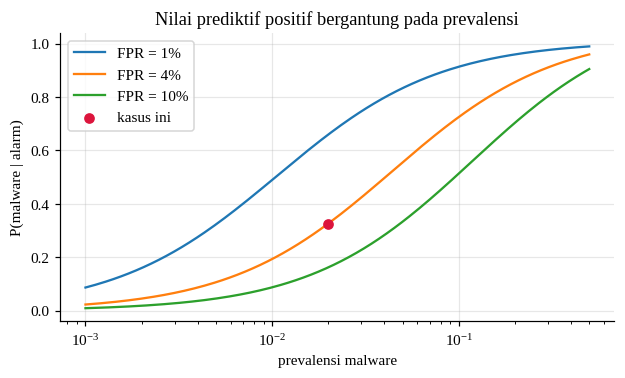

In [5]:
prevalensi = np.logspace(-3, np.log10(0.5), 200)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for f in (0.01, 0.04, 0.10):
    ppv_f = sens * prevalensi / (sens * prevalensi + f * (1 - prevalensi))
    ax.plot(prevalensi, ppv_f, label=f"FPR = {f:.0%}")
ax.scatter([prev], [float(ppv)], color="crimson", zorder=3, label="kasus ini")
ax.set(xscale="log", xlabel="prevalensi malware", ylabel="P(malware | alarm)",
       title="Nilai prediktif positif bergantung pada prevalensi")
ax.legend()
plt.show()

**Interpretasi.** Peluang total alarm adalah 291/5000 = 0,0582, dan peluang file yang diberi alarm memang *malware* adalah 95/291 = 0,3265. Jadi walaupun detektor mengenali 95% *malware*, hanya sekitar sepertiga alarmnya yang benar. Simulasi menguatkan hal ini: dari 58.107 alarm hanya 18.937 yang *malware* (0,3259). Sebaliknya, file yang tidak diberi alarm hampir pasti bersih, yaitu dengan peluang 0,99894.

Grafik memperlihatkan sebabnya. Nilai prediktif positif sangat dipengaruhi prevalensi (*base rate*). Dengan prevalensi 2% dan *false positive* 4% hasilnya 32,6%; jika *false positive* turun menjadi 1% nilainya naik menjadi sekitar 66%, sedangkan pada 10% turun menjadi sekitar 16%. Kesimpulannya, mengevaluasi detektor hanya dari angka sensitivitas bisa menyesatkan; tingkat *false positive* dan prevalensi harus ikut dilihat.

**Kesimpulan kasus.** Alarm dari detektor berakurasi tinggi pun bisa lebih sering salah daripada benar bila kejadian yang dicari tergolong langka.

## P3. Penyaring *spam* dengan *Naive Bayes*  *(tingkat: Menengah)*

**Skenario.** Dari 11 surel berlabel (5 *spam*, 6 *ham*) dibangun penyaring sederhana. Tiga surel baru kemudian diklasifikasikan, termasuk satu surel yang isinya campuran kata *spam* dan kata perkuliahan.

**Konsep.** Pengklasifikasi *Naive Bayes* memilih kelas dengan peluang *posterior* terbesar, P(kelas | kata) ∝ P(kelas) ∏ P(kata | kelas), dengan asumsi kata-kata saling bebas bersyarat pada kelasnya. Peluang tiap kata diestimasi dari frekuensi di data latih dengan *smoothing* Laplace, P(kata | kelas) = (cacah + 1)/(total kata kelas + V), supaya kata yang belum pernah muncul di satu kelas tidak membuat seluruh hasil kali menjadi nol. Perhitungan dilakukan manual dalam bentuk logaritma, lalu dibandingkan dengan `MultinomialNB` dari *scikit-learn*.

In [6]:
data = pd.DataFrame({
    "teks": [
        "menang hadiah gratis klik link sekarang",
        "diskon besar gratis klik promo sekarang",
        "klik link hadiah gratis transfer pulsa",
        "promo pinjaman cepat tanpa jaminan klik",
        "selamat anda menang hadiah transfer sekarang",
        "jadwal kuliah probabilitas besok pukul delapan",
        "tugas statistika dikumpulkan lewat email dosen",
        "rapat kelompok proyek basis data besok",
        "mohon kirim laporan praktikum sebelum jumat",
        "diskusi tugas akhir dengan dosen pembimbing",
        "link zoom kuliah probabilitas sudah dikirim",
    ],
    "label": ["spam"] * 5 + ["ham"] * 6,
})

vec = CountVectorizer()
X = vec.fit_transform(data.teks)
kata = vec.get_feature_names_out()
V, alpha = len(kata), 1                      # ukuran kosakata, smoothing Laplace
kelas = ["ham", "spam"]
prior = data.label.value_counts(normalize=True)
cacah = {}
for k in kelas:
    baris_k = X[(data.label == k).to_numpy()]
    cacah[k] = np.asarray(baris_k.sum(axis=0)).ravel()
lik = {k: (cacah[k] + alpha) / (cacah[k].sum() + alpha * V) for k in kelas}

def posterior(teks):
    x = vec.transform([teks]).toarray().ravel()
    log_skor = np.array([np.log(prior[k]) + x @ np.log(lik[k]) for k in kelas])
    skor = np.exp(log_skor - log_skor.max())
    return dict(zip(kelas, skor / skor.sum()))

print("Ukuran kosakata V =", V)
print("Prior             :", prior.round(3).to_dict())
print("Total kata spam   :", cacah["spam"].sum(), "| total kata ham:", cacah["ham"].sum())

Ukuran kosakata V = 47
Prior             : {'ham': 0.545, 'spam': 0.455}
Total kata spam   : 30 | total kata ham: 36


In [7]:
uji = ["klik link hadiah gratis sekarang",
       "jadwal kuliah statistika besok",
       "link tugas probabilitas gratis klik"]
nb = MultinomialNB(alpha=1).fit(X, data.label)
idx_spam = list(nb.classes_).index("spam")

baris = []
for teks in uji:
    baris.append({"email": teks,
                  "P(spam) manual": posterior(teks)["spam"],
                  "P(spam) sklearn": nb.predict_proba(vec.transform([teks]))[0, idx_spam]
                  })
hasil = pd.DataFrame(baris)
hasil["keputusan"] = np.where(hasil["P(spam) manual"] > 0.5, "spam", "ham")
print(hasil.round(4).to_string(index=False))
catat("P3", "P(spam | email ke-3)", hasil.iloc[2, 1], hasil.iloc[2, 2], np.nan)

                              email  P(spam) manual  P(spam) sklearn keputusan
   klik link hadiah gratis sekarang          0.9983           0.9983      spam
     jadwal kuliah statistika besok          0.0303           0.0303       ham
link tugas probabilitas gratis klik          0.8017           0.8017      spam


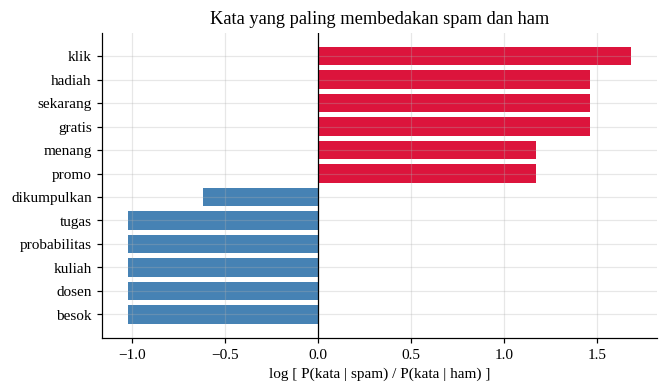

In [8]:
lr = np.log(lik["spam"]) - np.log(lik["ham"])
urut = np.argsort(lr)
pilih = np.r_[urut[:6], urut[-6:]]

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.barh(kata[pilih], lr[pilih], color=np.where(lr[pilih] > 0, "crimson", "steelblue"))
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="log [ P(kata | spam) / P(kata | ham) ]",
       title="Kata yang paling membedakan spam dan ham")
plt.show()

**Interpretasi.** Kosakata terdiri dari 47 kata dengan *prior* *ham* 0,545 dan *spam* 0,455. Untuk surel "klik *link* hadiah gratis sekarang" peluang *spam* adalah 0,9983, sedangkan "jadwal kuliah statistika besok" hanya 0,0303 sehingga digolongkan *ham*. Surel campuran "*link* tugas probabilitas gratis klik" mendapat 0,8017; kata "gratis" dan "klik" lebih kuat menarik ke *spam* daripada "tugas" dan "probabilitas" menarik ke *ham*. Kata "*link*" sendiri hampir netral karena muncul di kedua kelas.

Angka dari perhitungan manual sama dengan keluaran `predict_proba` pada empat desimal, sehingga rumus dan implementasi pustaka saling membenarkan. Grafik di atas menunjukkan kata yang paling membedakan kelas. Perlu dicatat bahwa data latihnya sangat kecil dan kata di luar kosakata diabaikan oleh `CountVectorizer`, jadi contoh ini ditujukan untuk memahami mekanismenya, bukan untuk dipakai sebagai penyaring sungguhan.

**Kesimpulan kasus.** *Naive Bayes* pada dasarnya penerapan teorema Bayes berulang; hasil manual dan *scikit-learn* identik.

## P4. Keandalan arsitektur *server* seri-paralel  *(tingkat: Menengah)*

**Skenario.** Sebuah layanan web terdiri dari satu *load balancer* (keandalan 0,999), tiga *server* aplikasi (masing-masing 0,95, sistem tetap jalan bila minimal dua hidup), dan dua basis data (masing-masing 0,98, cukup satu yang hidup). Berapa keandalan sistem keseluruhan, dan komponen mana yang paling menguntungkan untuk ditambah?

**Konsep.** Komponen yang disusun seri harus hidup semuanya sehingga keandalannya dikalikan; komponen paralel gagal hanya bila semuanya gagal, R = 1 − ∏(1 − Rᵢ). Bagian "minimal 2 dari 3 *server*" dihitung dengan distribusi binomial, P(X ≥ 2). Keandalan sistem dihitung tiga cara: rumus, enumerasi seluruh 2⁶ = 64 keadaan komponen dengan `itertools.product`, dan simulasi Monte Carlo 500.000 kali.

In [9]:
r_lb, r_app, r_db = 0.999, 0.95, 0.98       # keandalan tiap komponen
# arsitektur: 1 load balancer -> 3 server aplikasi (cukup 2 hidup)
#             -> 2 basis data (cukup 1 hidup)

# cara 1: rumus peluang
R_app = stats.binom.sf(1, 3, r_app)             # P(minimal 2 dari 3 server hidup)
R_db = 1 - (1 - r_db) ** 2
R_rumus = r_lb * R_app * R_db

# cara 2: enumerasi 2^6 = 64 keadaan komponen
komp = [r_lb, r_app, r_app, r_app, r_db, r_db]
R_enum = 0.0
for s in itertools.product([0, 1], repeat=6):
    peluang = np.prod([q if hidup else 1 - q for q, hidup in zip(komp, s)])
    lb, a1, a2, a3, d1, d2 = s
    if lb and (a1 + a2 + a3 >= 2) and (d1 or d2):
        R_enum += peluang

# cara 3: simulasi Monte Carlo
T = 500_000
U = rng.random((T, 6)) < np.array(komp)
R_sim = (U[:, 0] & (U[:, 1:4].sum(axis=1) >= 2) & (U[:, 4] | U[:, 5])).mean()

print(f"R server aplikasi (2 dari 3) : {R_app:.6f}")
print(f"R basis data (paralel)       : {R_db:.6f}")
print(f"R sistem - rumus             : {R_rumus:.6f}")
print(f"R sistem - enumerasi         : {R_enum:.6f}")
print(f"R sistem - simulasi          : {R_sim:.6f}")
print(f"Perkiraan downtime per tahun : {(1 - R_rumus) * 525_600:.0f} menit")
catat("P4", "keandalan sistem", R_rumus, R_enum, R_sim, se_prop(R_rumus, T))

R server aplikasi (2 dari 3) : 0.992750
R basis data (paralel)       : 0.999600
R sistem - rumus             : 0.991361
R sistem - enumerasi         : 0.991361
R sistem - simulasi          : 0.991502
Perkiraan downtime per tahun : 4541 menit


                           keandalan  downtime (menit/tahun)
Dasar (1 LB, 3 app, 2 DB)    0.99136              4540.89644
App 4 server (min. 2)        0.99812               988.22074
DB 3 replika                 0.99175              4336.55954
Load balancer dobel          0.99235              4019.83734
Semua ditingkatkan           0.99951               257.67312


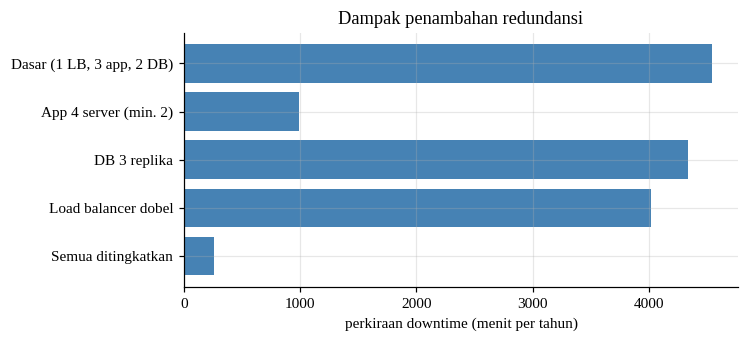

In [10]:
def R(r_lb=0.999, r_app=0.95, r_db=0.98, n_lb=1, n_app=3, k=2, n_db=2):
    return ((1 - (1 - r_lb) ** n_lb) * stats.binom.sf(k - 1, n_app, r_app)
            * (1 - (1 - r_db) ** n_db))

desain = {
    "Dasar (1 LB, 3 app, 2 DB)": R(),
    "App 4 server (min. 2)": R(n_app=4),
    "DB 3 replika": R(n_db=3),
    "Load balancer dobel": R(n_lb=2),
    "Semua ditingkatkan": R(n_app=4, n_db=3, n_lb=2),
}
tabel = pd.DataFrame({"keandalan": desain})
tabel["downtime (menit/tahun)"] = (1 - tabel.keandalan) * 525_600
print(tabel.round(5).to_string())

fig, ax = plt.subplots(figsize=(6.5, 3.0))
ax.barh(tabel.index[::-1], tabel["downtime (menit/tahun)"][::-1], color="steelblue")
ax.set(xlabel="perkiraan downtime (menit per tahun)",
       title="Dampak penambahan redundansi")
plt.show()

**Interpretasi.** Keandalan bagian *server* aplikasi 0,99275 dan basis data 0,9996, sehingga sistem secara keseluruhan 0,991361. Rumus dan enumerasi memberi angka yang sama persis, simulasi memberi 0,991502 yang masih dalam galat bakunya. Jika angka ini diperlakukan sebagai ketersediaan tahunan, *downtime*-nya sekitar 4.541 menit per tahun atau kira-kira 76 jam.

Perbandingan rancangan menunjukkan bahwa tidak semua redundansi sama manfaatnya. Menambah satu *server* aplikasi (dari 3 menjadi 4, tetap butuh minimal 2) menurunkan *downtime* menjadi 988 menit, jauh lebih besar daripada menambah replika basis data (4.337 menit) atau menggandakan *load balancer* (4.020 menit). Alasannya, komponen paling lemah ada di lapisan aplikasi (0,95), sehingga di situ tambahan redundansi paling berpengaruh. Jika ketiganya ditingkatkan, *downtime* turun menjadi sekitar 258 menit.

**Kesimpulan kasus.** Keandalan sistem ditentukan oleh bagian yang paling lemah; redundansi sebaiknya ditambahkan di sana lebih dulu.

## P5. Rantai Markov untuk navigasi pengguna situs belanja  *(tingkat: Lanjut)*

**Skenario.** Perilaku pengunjung sebuah toko daring dimodelkan sebagai perpindahan antar lima halaman (Beranda, Katalog, Detail, Keranjang, Checkout) dengan peluang transisi yang diketahui. Yang ingin dijawab: halaman mana yang paling sering dikunjungi dalam jangka panjang, dan rata-rata berapa klik pengunjung kembali ke Beranda?

**Konsep.** Rantai Markov dengan matriks transisi P memenuhi π(n+1) = π(n)P. Untuk rantai yang ergodik, distribusinya konvergen ke distribusi stasioner π yang memenuhi πP = π dan ∑πᵢ = 1. Distribusi ini dicari dengan dua cara, yaitu vektor eigen kiri untuk nilai eigen 1 dan penyelesaian sistem linear, lalu dibandingkan dengan simulasi 300.000 klik. Waktu kembali rata-rata ke suatu keadaan sama dengan 1/πᵢ. Sebagai pembanding, PageRank dengan faktor redaman 0,85 dihitung manual dan dengan `networkx.pagerank`.

In [12]:
halaman = ["Beranda", "Katalog", "Detail", "Keranjang", "Checkout"]
P = np.array([[0.10, 0.60, 0.20, 0.05, 0.05],
              [0.25, 0.20, 0.45, 0.05, 0.05],
              [0.15, 0.30, 0.15, 0.30, 0.10],
              [0.20, 0.10, 0.15, 0.10, 0.45],
              [0.70, 0.10, 0.10, 0.05, 0.05]])
assert np.allclose(P.sum(axis=1), 1)

# posisi pengunjung setelah n klik, mulai dari Beranda
awal = np.array([1, 0, 0, 0, 0])
for n in (1, 2, 5, 20):
    print(f"n = {n:2d}", (awal @ np.linalg.matrix_power(P, n)).round(4))

# distribusi stasioner (1): vektor eigen kiri untuk nilai eigen 1
nilai, vektor = np.linalg.eig(P.T)
pi_eig = np.real(vektor[:, np.argmin(np.abs(nilai - 1))])
pi_eig /= pi_eig.sum()

# distribusi stasioner (2): selesaikan pi (P - I) = 0 dengan sum(pi) = 1
A = np.vstack([P.T - np.eye(5), np.ones(5)])
pi_lin = np.linalg.lstsq(A, np.r_[np.zeros(5), 1], rcond=None)[0]

# simulasi 300.000 klik
langkah = 300_000
kum, u = P.cumsum(axis=1), rng.random(langkah)
jejak = np.empty(langkah, dtype=int)
s = 0
for t in range(langkah):
    s = min(np.searchsorted(kum[s], u[t]), 4)
    jejak[t] = s
pi_sim = np.bincount(jejak, minlength=5) / langkah

tabel = pd.DataFrame({"eigen": pi_eig, "linear": pi_lin, "simulasi": pi_sim},
                     index=halaman)
print("\n", tabel.round(4), sep="")
kembali = np.diff(np.flatnonzero(jejak == 0)).mean()
print(f"\nRata-rata klik untuk kembali ke Beranda: simulasi {kembali:.3f}, "
      f"teori 1/pi = {1 / pi_eig[0]:.3f}")
catat("P5", "pi(Beranda)", pi_eig[0], pi_lin[0], pi_sim[0], se_batch(jejak == 0))

n =  1 [0.1  0.6  0.2  0.05 0.05]
n =  2 [0.235  0.25   0.3325 0.1025 0.08  ]
n =  5 [0.2366 0.2961 0.2411 0.1177 0.1084]
n = 20 [0.2337 0.2953 0.2448 0.1171 0.1091]

            eigen  linear  simulasi
Beranda    0.2337  0.2337    0.2336
Katalog    0.2953  0.2953    0.2957
Detail     0.2448  0.2448    0.2450
Keranjang  0.1171  0.1171    0.1170
Checkout   0.1091  0.1091    0.1088

Rata-rata klik untuk kembali ke Beranda: simulasi 4.281, teori 1/pi = 4.279


           stasioner  PageRank manual  PageRank networkx
Beranda       0.2337           0.2354             0.2354
Katalog       0.2953           0.2783             0.2783
Detail        0.2448           0.2331             0.2331
Keranjang     0.1171           0.1275             0.1275
Checkout      0.1091           0.1257             0.1257


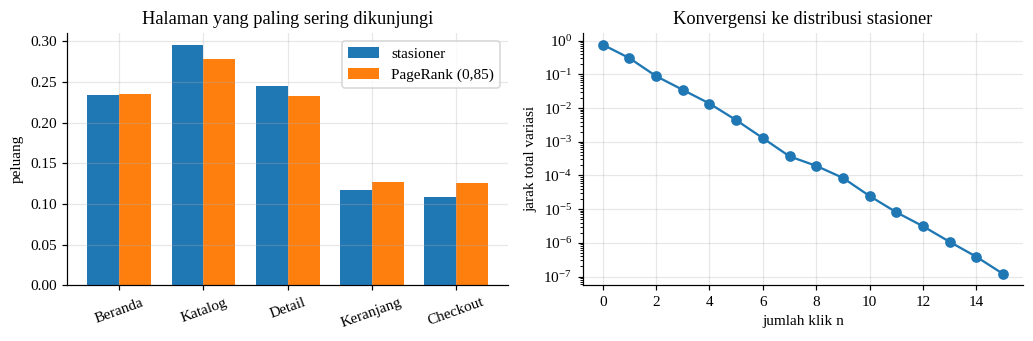

In [13]:
damping = 0.85
G = nx.DiGraph()
for i, a in enumerate(halaman):
    for j, b in enumerate(halaman):
        G.add_edge(a, b, weight=P[i, j])
pr_nx = nx.pagerank(G, alpha=damping, weight="weight")

pr = np.ones(5) / 5                               # PageRank manual (power iteration)
for _ in range(200):
    pr = (1 - damping) / 5 + damping * pr @ P
print(pd.DataFrame({"stasioner": pi_eig, "PageRank manual": pr,
                    "PageRank networkx": [pr_nx[h] for h in halaman]},
                   index=halaman).round(4))

jarak = [0.5 * np.abs(awal @ np.linalg.matrix_power(P, n) - pi_eig).sum()
         for n in range(16)]
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
xs, lebar = np.arange(5), 0.38
ax[0].bar(xs - lebar / 2, pi_eig, lebar, label="stasioner")
ax[0].bar(xs + lebar / 2, pr, lebar, label="PageRank (0,85)")
ax[0].set_xticks(xs, halaman, rotation=20)
ax[0].set(ylabel="peluang", title="Halaman yang paling sering dikunjungi")
ax[0].legend()
ax[1].semilogy(range(16), jarak, "o-")
ax[1].set(xlabel="jumlah klik n", ylabel="jarak total variasi",
          title="Konvergensi ke distribusi stasioner")
plt.tight_layout()
plt.show()

**Interpretasi.** Setelah 20 klik, distribusi posisi pengunjung sudah tidak berubah dari (0,2337; 0,2953; 0,2448; 0,1171; 0,1091). Cara eigen dan cara sistem linear menghasilkan angka identik, dan simulasi hanya berbeda pada desimal ketiga atau keempat. Katalog adalah halaman yang paling sering dikunjungi (29,5%), sedangkan Checkout paling jarang (10,9%). Rata-rata kembali ke Beranda ditempuh dalam 1/0,2337 = 4,279 klik menurut teori dan 4,288 klik menurut simulasi.

PageRank memberi hasil yang lebih mendatar karena faktor redaman memasukkan kemungkinan "loncat acak": Katalog turun ke 0,2783 sementara Checkout naik ke 0,1257. Hasil manual dan `networkx` sama sampai empat desimal. Grafik kedua memperlihatkan jarak total variasi ke distribusi stasioner turun hampir lurus pada skala logaritmik, artinya konvergensinya berlangsung secara geometris; sekitar 15 klik sudah cukup untuk praktis mencapai kondisi stabil.

**Kesimpulan kasus.** Dua metode analitik dan simulasi menghasilkan distribusi stasioner yang sama, yang dapat dipakai untuk menilai halaman mana yang paling berpengaruh.

## P6. Hukum bilangan besar dan teorema limit pusat pada waktu respons  *(tingkat: Menengah)*

**Skenario.** Waktu respons sebuah API (rata-rata 200 ms) berdistribusi eksponensial, sehingga sangat miring ke kanan. Apa yang terjadi pada rata-rata sampel bila ukuran sampelnya diperbesar, dan seberapa baik hampiran normal untuk peluang rata-rata 30 *request* melebihi 230 ms?

**Konsep.** Hukum bilangan besar menyatakan rata-rata sampel mendekati nilai harapan bila n membesar. Teorema limit pusat menyatakan rata-rata n pengamatan bebas mendekati N(μ, σ²/n) walaupun sebaran asalnya tidak normal. Untuk distribusi eksponensial, simpangan baku dan nilai harapannya sama (σ = μ = 200) dan koefisien kemiringan rata-rata sampel adalah 2/√n. Karena jumlah n eksponensial berdistribusi Erlang, peluang eksaknya tersedia sebagai penjumlahan suku Poisson sehingga mutu hampiran normal dapat dinilai.

In [14]:
mu = 200.0                          # rata-rata waktu respons (ms), sebaran eksponensial
ukuran = [1, 5, 30, 200]
rata_sampel, baris = {}, []
for n in ukuran:
    rata = rng.exponential(mu, size=(20_000, n)).mean(axis=1)
    rata_sampel[n] = rata
    baris.append({"n": n, "rata-rata": rata.mean(), "SD simulasi": rata.std(ddof=1),
                  "SD teori": mu / np.sqrt(n), "skewness": stats.skew(rata),
                  "skew teori": 2 / np.sqrt(n)})
print(pd.DataFrame(baris).round(3).to_string(index=False))

# P(rata-rata 30 request > 230 ms): jumlah 30 eksponensial ~ Gamma(30) (Erlang)
n, batas = 30, 230
a = n * batas / mu
rumus = sum(math.exp(-a) * a**j / math.factorial(j) for j in range(n))   # Poisson CDF
gamma = stats.gamma.sf(batas, a=n, scale=mu / n)
normal = stats.norm.sf(batas, mu, mu / np.sqrt(n))
sim = (rata_sampel[30] > batas).mean()
print(f"\nP(rata-rata 30 request > {batas} ms)")
print(f"  rumus Erlang (jumlah suku Poisson) : {rumus:.5f}")
print(f"  scipy gamma.sf                     : {gamma:.5f}")
print(f"  hampiran normal (CLT)              : {normal:.5f}")
print(f"  simulasi                           : {sim:.5f}")
catat("P6", "P(rata-rata 30 request > 230 ms)", rumus, gamma, sim, se_prop(rumus, 20_000))

  n  rata-rata  SD simulasi  SD teori  skewness  skew teori
  1    199.701      198.779   200.000     1.992       2.000
  5    199.893       89.328    89.443     0.881       0.894
 30    200.347       36.606    36.515     0.374       0.365
200    199.904       14.139    14.142     0.152       0.141

P(rata-rata 30 request > 230 ms)
  rumus Erlang (jumlah suku Poisson) : 0.19935
  scipy gamma.sf                     : 0.19935
  hampiran normal (CLT)              : 0.20566
  simulasi                           : 0.20145


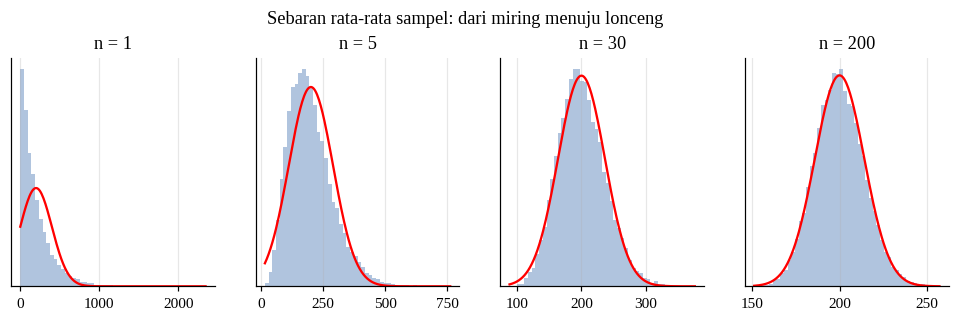

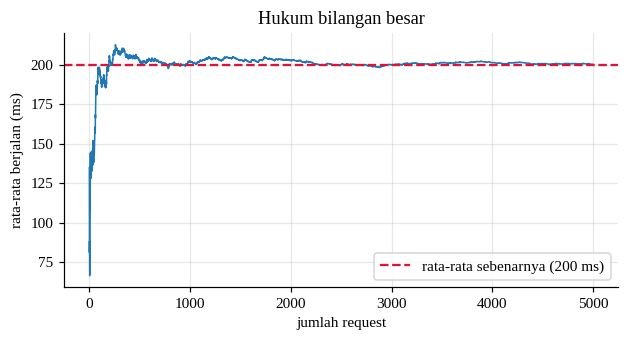

In [15]:
fig, ax = plt.subplots(1, 4, figsize=(11, 2.7))
for a_, n in zip(ax, ukuran):
    rata = rata_sampel[n]
    a_.hist(rata, bins=50, density=True, color="lightsteelblue")
    g = np.linspace(rata.min(), rata.max(), 200)
    a_.plot(g, stats.norm.pdf(g, mu, mu / np.sqrt(n)), "r", lw=1.5)
    a_.set_title(f"n = {n}")
    a_.set_yticks([])
fig.suptitle("Sebaran rata-rata sampel: dari miring menuju lonceng", y=1.04)
plt.show()

x = rng.exponential(mu, size=5000)
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(np.cumsum(x) / np.arange(1, 5001), lw=1)
ax.axhline(mu, color="crimson", ls="--", label="rata-rata sebenarnya (200 ms)")
ax.set(xlabel="jumlah request", ylabel="rata-rata berjalan (ms)",
       title="Hukum bilangan besar")
ax.legend()
plt.show()

**Interpretasi.** Simpangan baku rata-rata sampel mengikuti μ/√n dengan baik (misalnya 36,84 hasil simulasi terhadap 36,52 teori pada n = 30), dan kemiringannya turun dari 1,99 pada n = 1 menjadi 0,90; 0,37; dan 0,13 untuk n = 5, 30, dan 200, sesuai nilai teori 2/√n. Histogram pada grafik berubah dari bentuk miring menjadi lonceng yang menempel pada kurva normal.

Untuk P(rata-rata 30 *request* > 230 ms), rumus Erlang dan `gamma.sf` memberi 0,19935, simulasi 0,20355, sedangkan hampiran normal memberi 0,20566. Hampiran normal menyimpang sekitar 0,006 pada n = 30 karena sebarannya masih sedikit miring. Kurva rata-rata berjalan memperlihatkan hukum bilangan besar: pada awal ia berayun lebar, dan baru stabil di sekitar 200 ms setelah beberapa ribu *request*. Dalam pemantauan, artinya rata-rata latensi dari sampel kecil tidak boleh dibaca terlalu serius.

**Kesimpulan kasus.** Rata-rata sampel menjadi lebih stabil dan lebih simetris dengan bertambahnya n, tetapi hampiran normal pada n kecil masih menyisakan galat.

## P7. Aturan kompleksitas *password* dengan inklusi-eksklusi  *(tingkat: Menengah)*

**Skenario.** Sebuah *password* acak sepanjang 8 karakter diambil dari 62 simbol (26 huruf kecil, 26 huruf besar, 10 angka). Sistem mewajibkan minimal satu huruf kecil, satu huruf besar, dan satu angka. Berapa peluang *password* acak memenuhi aturan itu?

**Konsep.** Dengan A, B, C sebagai kejadian "tidak ada huruf kecil", "tidak ada huruf besar", dan "tidak ada angka", peluang yang dicari adalah 1 − P(A ∪ B ∪ C). Prinsip inklusi-eksklusi memberi P(A ∪ B ∪ C) = ∑P(·) − ∑P(·∩·) + P(A ∩ B ∩ C), dan setiap suku berbentuk ((N − ukuran kelas yang dibuang)/N)ᴸ. Rumus umumnya diuji lebih dulu pada alfabet kecil (6 simbol, panjang 5) yang seluruh 7.776 stringnya bisa dienumerasi, baru kemudian dipakai pada kasus sebenarnya dengan pecahan eksak `sympy` dan simulasi.

In [16]:
def p_lengkap(ukuran_kelas, L):
    """P(string acak sepanjang L memuat minimal satu karakter dari setiap kelas).
    Inklusi-eksklusi atas kejadian 'kelas ke-i tidak muncul'."""
    N = sum(ukuran_kelas)
    total = 0
    for r in range(len(ukuran_kelas) + 1):
        for S in itertools.combinations(ukuran_kelas, r):
            total += (-1) ** r * sp.Rational(N - sum(S), N) ** L
    return total

# uji rumus dengan enumerasi pada alfabet kecil {a,b}, {A,B}, {1,2} dan L = 5
kecil = ["ab", "AB", "12"]
alfabet = "".join(kecil)
cocok = sum(all(any(c in kls for c in teks) for kls in kecil)
            for teks in itertools.product(alfabet, repeat=5))
print("Enumerasi", len(alfabet) ** 5, "string:", cocok, "memenuhi syarat ->",
      sp.Rational(cocok, 6**5))
print("Rumus inklusi-eksklusi      :", p_lengkap([2, 2, 2], 5))

Enumerasi 7776 string: 4800 memenuhi syarat -> 50/81
Rumus inklusi-eksklusi      : 50/81


P(password 8 karakter memenuhi syarat) = 0.731226
Ruang password 62^8                    = 218.340.105.584.896
Jumlah password yang valid             = 159.655.911.367.680
Simulasi 1.000.000 password            = 0.731505
Panjang minimal agar peluang >= 99%    = 27


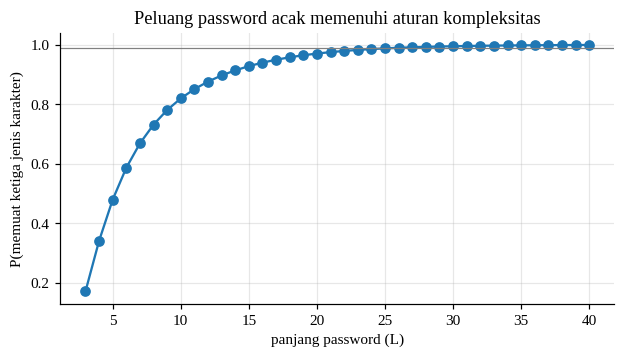

In [17]:
kelas_pw = [26, 26, 10]                          # huruf kecil, huruf besar, angka
L = 8
p_exact = p_lengkap(kelas_pw, L)
rumus = (1 - 2 * (36 / 62) ** L - (52 / 62) ** L
         + 2 * (26 / 62) ** L + (10 / 62) ** L)
print("P(password 8 karakter memenuhi syarat) =", round(float(p_exact), 6))
print("Ruang password 62^8                    =", titik(62**L))
print("Jumlah password yang valid             =", titik(int(p_exact * 62**L)))

M = 1_000_000
pw = rng.integers(0, 62, size=(M, L))
ada_kecil = (pw < 26).any(axis=1)
ada_besar = ((pw >= 26) & (pw < 52)).any(axis=1)
ada_angka = (pw >= 52).any(axis=1)
sim = (ada_kecil & ada_besar & ada_angka).mean()
print("Simulasi 1.000.000 password            =", round(sim, 6))

panjang = np.arange(3, 41)
pL = np.array([float(p_lengkap(kelas_pw, l)) for l in panjang])
print("Panjang minimal agar peluang >= 99%    =", panjang[np.argmax(pL >= 0.99)])
catat("P7", "P(password 8 karakter lengkap)", rumus, float(p_exact), sim,
      se_prop(rumus, M))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(panjang, pL, "o-")
ax.axhline(0.99, color="gray", lw=0.8)
ax.set(xlabel="panjang password (L)", ylabel="P(memuat ketiga jenis karakter)",
       title="Peluang password acak memenuhi aturan kompleksitas")
plt.show()

**Interpretasi.** Pada alfabet kecil, enumerasi menemukan 4.800 dari 7.776 *string* memenuhi syarat, yaitu 50/81, dan rumus inklusi-eksklusi memberi pecahan yang sama persis. Setelah rumusnya terbukti benar, peluang untuk *password* 8 karakter dihitung: 0,731226, sedangkan simulasi sejuta *password* memberi 0,731724. Dari 62⁸ = 218.340.105.584.896 kombinasi, ada 159.655.911.367.680 yang valid.

Artinya sekitar 27% *password* acak sepanjang 8 karakter ditolak oleh aturan tersebut, tetapi bagi penyerang yang menebak, ruang pencariannya hanya menyusut sekitar 27%. Setiap tambahan satu karakter melipatgandakan ruang itu 62 kali, jadi menambah panjang jauh lebih berpengaruh daripada aturan komposisi. Grafik memperlihatkan peluang lolos naik dengan cepat, dan baru melewati 99% pada panjang 27.

**Kesimpulan kasus.** Rumus inklusi-eksklusi terbukti benar lewat enumerasi kecil dan sesuai dengan simulasi besar.

# Bagian B - Distribusi Diskrit

## D1. Distribusi binomial: paket hilang pada jaringan  *(tingkat: Dasar)*

**Skenario.** Sebuah *frame* data terdiri dari 20 paket, dan tiap paket hilang dengan peluang 0,08 secara independen. *Frame* masih bisa dipulihkan oleh kode koreksi galat bila paket yang hilang paling banyak 2. Berapa peluang *frame* berhasil, dan berapa paket hilang yang diharapkan?

**Konsep.** Jumlah paket hilang X ~ Binomial(n = 20, p = 0,08) dengan P(X = k) = C(n,k)pᵏ(1−p)ⁿ⁻ᵏ, E[X] = np, dan Var[X] = np(1−p). Fungsi massa peluang dihitung manual dengan `math.comb` dan dibandingkan dengan `stats.binom`; nilai harapan dan varians dihitung dari definisi (∑x·P(x) dan E[X²] − E[X]²), dari rumus, dan dari simulasi.

In [18]:
n, p = 20, 0.08                       # 20 paket per frame, tiap paket hilang w.p. 8%
x = np.arange(n + 1)

pmf_manual = np.array([math.comb(n, k) * p**k * (1 - p) ** (n - k) for k in x])
pmf_scipy = stats.binom.pmf(x, n, p)
print("selisih terbesar PMF manual vs scipy:", np.abs(pmf_manual - pmf_scipy).max())

# frame dapat dipulihkan bila paket hilang paling banyak 2: P(X <= 2)
print("P(X <= 2) manual :", round(pmf_manual[:3].sum(), 5))
print("P(X <= 2) scipy  :", round(stats.binom.cdf(2, n, p), 5))

# nilai harapan dan varians
E_def = (x * pmf_manual).sum()
V_def = (x**2 * pmf_manual).sum() - E_def**2
m, v = stats.binom.stats(n, p)
print(f"E[X]   : definisi {E_def:.4f} | np  = {n * p:.4f} | scipy {float(m):.4f}")
print(f"Var[X] : definisi {V_def:.4f} | npq = {n * p * (1 - p):.4f} "
      f"| scipy {float(v):.4f}")

# simulasi 300.000 frame
X = rng.binomial(n, p, size=300_000)
print(f"Simulasi : P(X<=2) = {(X <= 2).mean():.5f}, rata-rata = {X.mean():.4f}, "
      f"var = {X.var():.4f}")
catat("D1", "P(X <= 2)", pmf_manual[:3].sum(), stats.binom.cdf(2, n, p), (X <= 2).mean(),
      se_prop(pmf_manual[:3].sum(), 300_000))

selisih terbesar PMF manual vs scipy: 3.3306690738754696e-16
P(X <= 2) manual : 0.78795
P(X <= 2) scipy  : 0.78795
E[X]   : definisi 1.6000 | np  = 1.6000 | scipy 1.6000
Var[X] : definisi 1.4720 | npq = 1.4720 | scipy 1.4720
Simulasi : P(X<=2) = 0.78733, rata-rata = 1.6015, var = 1.4738


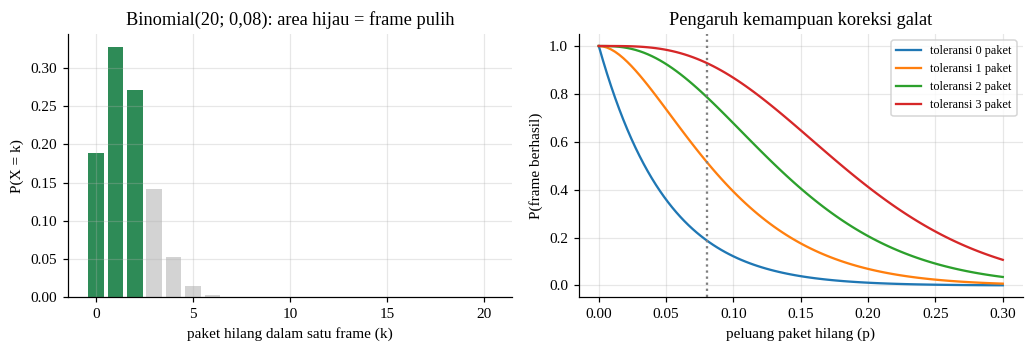

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.3))
warna = ["seagreen" if k <= 2 else "lightgray" for k in x]
ax[0].bar(x, pmf_manual, color=warna)
ax[0].set(xlabel="paket hilang dalam satu frame (k)", ylabel="P(X = k)",
          title="Binomial(20; 0,08): area hijau = frame pulih")
ps = np.linspace(0, 0.3, 100)
for toleransi in range(4):
    ax[1].plot(ps, stats.binom.cdf(toleransi, n, ps),
               label=f"toleransi {toleransi} paket")
ax[1].axvline(p, color="gray", ls=":")
ax[1].set(xlabel="peluang paket hilang (p)", ylabel="P(frame berhasil)",
          title="Pengaruh kemampuan koreksi galat")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Interpretasi.** Selisih terbesar antara PMF manual dan `scipy` hanya sekitar 3×10⁻¹⁶, jadi keduanya setara. Peluang *frame* berhasil P(X ≤ 2) adalah 0,78795 (simulasi 0,78716). Nilai harapan paket hilang 1,6 per *frame* dengan varians 1,472, dan angka dari definisi, rumus np dan np(1−p), serta `scipy` semuanya sama.

Tanpa koreksi galat peluang *frame* utuh hanya 0,92²⁰ ≈ 0,19. Grafik kanan memperlihatkan bahwa setiap tambahan toleransi satu paket menggeser kurva ke atas secara berarti, tetapi manfaatnya makin kecil di sekitar p = 0,08 dan sangat menurun bila p membesar.

**Kesimpulan kasus.** Binomial cocok untuk menghitung banyaknya kegagalan dari sejumlah percobaan independen yang tetap.

## D2. Distribusi geometrik: percobaan ulang koneksi (*retry*)  *(tingkat: Dasar)*

**Skenario.** Sebuah klien mencoba menyambung ke *server* dan tiap percobaan berhasil dengan peluang 0,7. Berapa peluang koneksi berhasil dalam 3 percobaan, berapa percobaan yang perlu disiapkan agar 99,9% *request* akhirnya berhasil, dan berapa rata-rata total waktu tunggu bila dipakai *exponential backoff* (100 ms, 200 ms, 400 ms, dan seterusnya)?

**Konsep.** Jumlah percobaan sampai sukses pertama X ~ Geometrik(p) dengan P(X = k) = (1−p)ᵏ⁻¹p, E[X] = 1/p, dan Var[X] = (1−p)/p². Distribusi ini tidak punya memori: P(X > a+b | X > a) = P(X > b). Waktu tunggu *backoff* sampai berhasil pada percobaan ke-X adalah 100(2ˣ⁻¹ − 1) ms, dan nilai harapannya sama dengan ∑ P(X > i)·100·2ⁱ⁻¹, deret geometrik dengan rasio 2(1−p).

In [20]:
p = 0.7                               # peluang sukses tiap percobaan koneksi
q = 1 - p
print("P(X <= 3): rumus 1 - q^3 =", round(1 - q**3, 5),
      "| scipy =", round(stats.geom.cdf(3, p), 5))
print("E[X] = 1/p =", round(1 / p, 4), "| Var[X] = q/p^2 =", round(q / p**2, 4))

# sifat tanpa memori: P(X > 5 | X > 2) = P(X > 3)
kiri = stats.geom.sf(5, p) / stats.geom.sf(2, p)
print("P(X>5 | X>2) =", round(kiri, 5), "| P(X>3) =", round(stats.geom.sf(3, p), 5))
print("Percobaan minimal agar 99,9% request akhirnya sukses:",
      int(stats.geom.ppf(0.999, p)))

# waktu tunggu total dengan exponential backoff 100, 200, 400, ... ms
def tunggu_harapan(p, dasar=100, suku=300):
    q = 1 - p
    return sum(q**i * dasar * 2 ** (i - 1) for i in range(1, suku))

X = rng.geometric(p, size=1_000_000)
tunggu = 100 * (2.0 ** (X - 1) - 1)
print("E[total tunggu] deret (p=0,7) :", round(tunggu_harapan(0.7), 2), "ms")
print("E[total tunggu] simulasi      :", round(tunggu.mean(), 2), "ms")
print("Untuk p = 0,45 deret 300 suku bernilai", f"{tunggu_harapan(0.45):.3e}",
      "ms (tidak konvergen)")
print("Simulasi: P(X<=3) =", round((X <= 3).mean(), 5),
      "| rata-rata X =", round(X.mean(), 4))
catat("D2", "P(X <= 3)", 1 - q**3, stats.geom.cdf(3, p), (X <= 3).mean(),
      se_prop(1 - q**3, 1_000_000))

P(X <= 3): rumus 1 - q^3 = 0.973 | scipy = 0.973
E[X] = 1/p = 1.4286 | Var[X] = q/p^2 = 0.6122
P(X>5 | X>2) = 0.027 | P(X>3) = 0.027
Percobaan minimal agar 99,9% request akhirnya sukses: 6
E[total tunggu] deret (p=0,7) : 75.0 ms
E[total tunggu] simulasi      : 74.66 ms
Untuk p = 0,45 deret 300 suku bernilai 1.309e+15 ms (tidak konvergen)
Simulasi: P(X<=3) = 0.97306 | rata-rata X = 1.4281


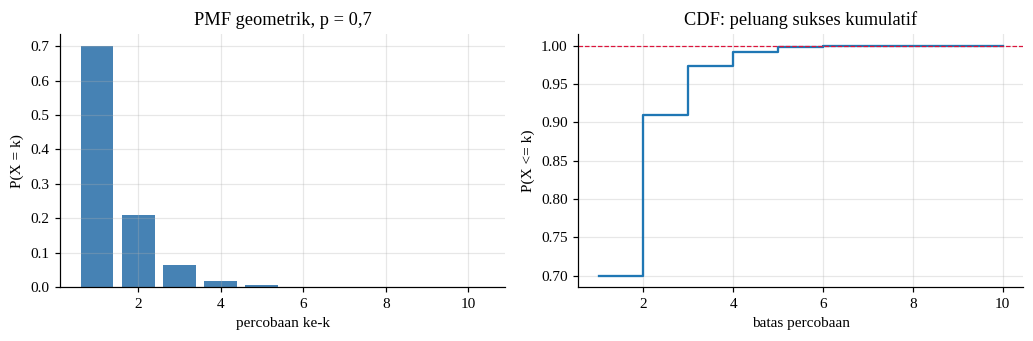

In [21]:
k = np.arange(1, 11)
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
ax[0].bar(k, stats.geom.pmf(k, p), color="steelblue")
ax[0].set(xlabel="percobaan ke-k", ylabel="P(X = k)", title="PMF geometrik, p = 0,7")
ax[1].step(k, stats.geom.cdf(k, p), where="post")
ax[1].axhline(0.999, color="crimson", ls="--", lw=0.8)
ax[1].set(xlabel="batas percobaan", ylabel="P(X <= k)",
          title="CDF: peluang sukses kumulatif")
plt.tight_layout()
plt.show()

**Interpretasi.** P(X ≤ 3) = 1 − 0,3³ = 0,973 dan sama dengan `geom.cdf` maupun simulasi (0,97308). Rata-rata percobaan 1,4286 dengan varians 0,6122. Sifat tanpa memori terbukti numerik: P(X>5 | X>2) = P(X>3) = 0,027. Agar 99,9% *request* akhirnya sukses, cukup disiapkan paling banyak 6 percobaan.

Dengan *exponential backoff*, rata-rata total tunggu adalah 75 ms menurut deret dan 75,01 ms menurut simulasi sejuta kali. Perlu dicatat bahwa deret itu hanya konvergen bila 2(1−p) < 1, yaitu p > 0,5. Pada p = 0,45 jumlah 300 sukunya sudah mencapai 1,3×10¹⁵ ms dan terus membesar, jadi *backoff* yang menggandakan waktu akan berbahaya bila peluang sukses tiap percobaan di bawah setengah.

**Kesimpulan kasus.** Geometrik memodelkan jumlah percobaan sampai sukses pertama dan memberi batas jumlah *retry* yang masuk akal.

## D3. Distribusi binomial negatif: pengujian sampai *bug* ke-r ditemukan  *(tingkat: Menengah)*

**Skenario.** Setiap kali menjalankan satu *test case*, peluang menemukan sebuah *bug* baru adalah 0,15. Tim ingin menemukan 3 *bug*. Berapa uji yang rata-rata dibutuhkan, dan berapa uji yang harus dianggarkan supaya 90% yakin ketiganya ditemukan?

**Konsep.** Total uji T sampai sukses ke-r berdistribusi binomial negatif, P(T = t) = C(t−1, r−1)pʳ(1−p)ᵗ⁻ʳ, dengan E[T] = r/p dan Var[T] = r(1−p)/p². Fungsi `scipy.stats.nbinom` menghitung banyaknya *kegagalan* sebelum sukses ke-r, sehingga T = gagal + r. Kejadian {T ≤ 20} ekuivalen dengan {minimal 3 sukses dalam 20 percobaan}, sehingga hasilnya juga bisa dicek dengan distribusi binomial.

In [22]:
r, p = 3, 0.15            # perlu 3 bug; tiap uji menemukan bug dengan peluang 0,15
# scipy.nbinom menghitung GAGAL sebelum sukses ke-r, jadi total uji T = gagal + r
t = np.arange(r, 81)
pmf_manual = np.array([math.comb(k - 1, r - 1) * p**r * (1 - p) ** (k - r) for k in t])
pmf_scipy = stats.nbinom.pmf(t - r, r, p)
print("selisih terbesar PMF manual vs scipy:", np.abs(pmf_manual - pmf_scipy).max())

print("E[T] = r/p            :", r / p)
print("Var[T] = r(1-p)/p^2   :", round(r * (1 - p) / p**2, 3))
print("P(T <= 20), nbinom    :", round(stats.nbinom.cdf(20 - r, r, p), 5))
print("P(Bin(20; 0,15) >= 3) :", round(stats.binom.sf(2, 20, p), 5),
      "(kejadian yang sama)")
t90 = int(stats.nbinom.ppf(0.9, r, p)) + r
print("Jumlah uji agar 90% yakin ketiga bug ditemukan:", t90)

T = rng.negative_binomial(r, p, size=400_000) + r
print(f"Simulasi : E[T] = {T.mean():.3f}, Var[T] = {T.var():.3f}, "
      f"P(T<=20) = {(T <= 20).mean():.5f}")
catat("D3", "P(T <= 20)", pmf_manual[t <= 20].sum(), stats.binom.sf(2, 20, p),
      (T <= 20).mean(), se_prop(stats.binom.sf(2, 20, p), 400_000))

selisih terbesar PMF manual vs scipy: 4.163336342344337e-17
E[T] = r/p            : 20.0
Var[T] = r(1-p)/p^2   : 113.333
P(T <= 20), nbinom    : 0.5951
P(Bin(20; 0,15) >= 3) : 0.5951 (kejadian yang sama)
Jumlah uji agar 90% yakin ketiga bug ditemukan: 34
Simulasi : E[T] = 19.991, Var[T] = 113.235, P(T<=20) = 0.59525


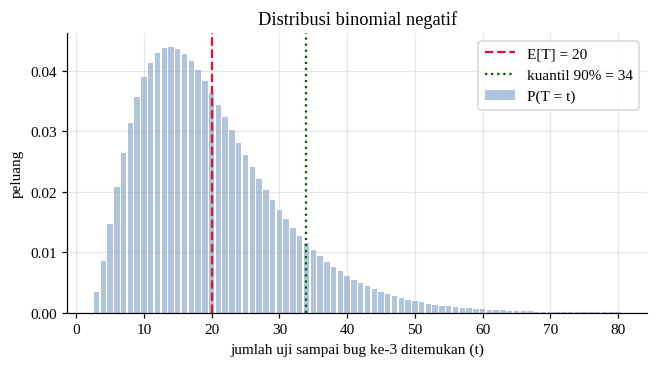

In [23]:
fig, ax = plt.subplots(figsize=(6.8, 3.3))
ax.bar(t, pmf_manual, color="lightsteelblue", label="P(T = t)")
ax.axvline(r / p, color="crimson", ls="--", label=f"E[T] = {r / p:.0f}")
ax.axvline(t90, color="darkgreen", ls=":", label=f"kuantil 90% = {t90}")
ax.set(xlabel="jumlah uji sampai bug ke-3 ditemukan (t)", ylabel="peluang",
       title="Distribusi binomial negatif")
ax.legend()
plt.show()

**Interpretasi.** Rata-rata uji yang dibutuhkan E[T] = 20 dengan varians 113,3, dan simulasi memberi 19,997 dan 113,385. Peluang selesai dalam 20 uji adalah 0,5951, sama untuk `nbinom.cdf` dan untuk P(Bin(20; 0,15) ≥ 3), yang membuktikan kesetaraan kedua kejadian itu.

Rata-rata 20 uji ternyata hanya memberi peluang sekitar 60% untuk selesai tepat waktu. Distribusinya berekor panjang ke kanan, sehingga untuk 90% keyakinan diperlukan 34 uji. Merencanakan anggaran pengujian dari rata-rata saja akan terlalu optimistis.

**Kesimpulan kasus.** Anggaran uji sebaiknya ditentukan dari kuantil distribusi, bukan dari nilai harapan.

## D4. Distribusi Poisson: *request* per detik pada API  *(tingkat: Dasar)*

**Skenario.** Sebuah *endpoint* API menerima rata-rata 4,5 *request* per detik. Seberapa sering dalam satu detik datang lebih dari 8 *request*, dan berapa kapasitas minimal agar peluang kelebihan beban tidak lebih dari 1%?

**Konsep.** Jika kejadian terjadi acak dengan laju konstan, banyaknya kejadian per satuan waktu X ~ Poisson(λ) dengan P(X = k) = e^(−λ)·λᵏ/k! dan E[X] = Var[X] = λ. Jumlah dua variabel Poisson independen juga Poisson dengan λ yang dijumlahkan. Poisson juga menghampiri Binomial(n, p) bila n besar dan p kecil dengan λ = np.

In [24]:
lam = 4.5                              # rata-rata request per detik
k = np.arange(0, 21)
pmf_manual = np.exp(-lam) * lam**k / np.array([math.factorial(i) for i in k])
pmf_scipy = stats.poisson.pmf(k, lam)
print("selisih terbesar PMF manual vs scipy:", np.abs(pmf_manual - pmf_scipy).max())
print("P(X = 4) :", round(stats.poisson.pmf(4, lam), 5))
print("P(X > 8) :", round(stats.poisson.sf(8, lam), 5), "(lebih dari 8 request/detik)")
print("E[X] = Var[X] = lambda =", lam, "| scipy:",
      [float(a) for a in stats.poisson.stats(lam)])

# kapasitas minimal c agar P(X > c) <= 1%
c = int(stats.poisson.ppf(0.99, lam))
print("Kapasitas c :", c, "| P(X > c) =", round(stats.poisson.sf(c, lam), 5))

# penjumlahan 3 endpoint independen, masing-masing Poisson(4,5) -> Poisson(13,5)
total = rng.poisson(lam, size=(300_000, 3)).sum(axis=1)
print("Total 3 endpoint: rata-rata", round(total.mean(), 3),
      "| var", round(total.var(), 3), "(teori 13,5)")
print("P(total > 20): simulasi", round((total > 20).mean(), 5),
      "| Poisson(13,5)", round(stats.poisson.sf(20, 3 * lam), 5))

# hampiran dari binomial dengan n besar, p kecil
bin_approx = stats.binom.pmf(k, 1000, lam / 1000)
print("Selisih terbesar Poisson vs Binomial(1000; 0,0045):",
      f"{np.abs(bin_approx - pmf_scipy).max():.5f}")
X = rng.poisson(lam, size=500_000)
print("Simulasi P(X > 8) =", round((X > 8).mean(), 5))
catat("D4", "P(X > 8)", 1 - pmf_manual[:9].sum(), stats.poisson.sf(8, lam),
      (X > 8).mean(), se_prop(stats.poisson.sf(8, lam), 500_000))

selisih terbesar PMF manual vs scipy: 1.942890293094024e-16
P(X = 4) : 0.18981
P(X > 8) : 0.04026 (lebih dari 8 request/detik)
E[X] = Var[X] = lambda = 4.5 | scipy: [4.5, 4.5]
Kapasitas c : 10 | P(X > c) = 0.00667
Total 3 endpoint: rata-rata 13.491 | var 13.484 (teori 13,5)
P(total > 20): simulasi 0.03463 | Poisson(13,5) 0.03509
Selisih terbesar Poisson vs Binomial(1000; 0,0045): 0.00041
Simulasi P(X > 8) = 0.03999


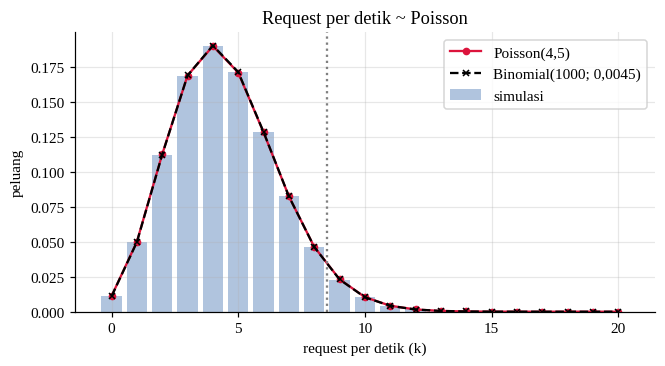

In [25]:
fig, ax = plt.subplots(figsize=(6.8, 3.3))
ax.bar(k, np.bincount(X, minlength=40)[:21] / len(X), color="lightsteelblue",
       label="simulasi")
ax.plot(k, pmf_scipy, "o-", color="crimson", ms=4, label="Poisson(4,5)")
ax.plot(k, bin_approx, "x--", color="black", ms=4, label="Binomial(1000; 0,0045)")
ax.axvline(8.5, color="gray", ls=":")
ax.set(xlabel="request per detik (k)", ylabel="peluang",
       title="Request per detik ~ Poisson")
ax.legend()
plt.show()

**Interpretasi.** Peluang tepat 4 *request* dalam satu detik 0,18981 dan peluang lebih dari 8 sebesar 0,04026 (simulasi 0,03983), jadi sekitar 4% detik akan melewati 8 *request*. Kapasitas c = 10 *request* per detik sudah menekan P(X > c) menjadi 0,00667, di bawah batas 1%. Tiga *endpoint* yang masing-masing Poisson(4,5) menghasilkan total dengan rata-rata 13,494 dan varians 13,45, mendekati Poisson(13,5), dan P(total > 20) = 0,03483 terhadap 0,03509 menurut teori.

Selisih terbesar antara Poisson(4,5) dan Binomial(1000; 0,0045) hanya 0,00041, jadi hampiran Poisson sangat baik. Sifat E[X] = Var[X] juga berguna dalam praktik: bila data hitungan nyata memiliki varians jauh lebih besar dari rata-ratanya, model Poisson tidak cocok dan kemungkinan ada *request* yang datang bergerombol.

**Kesimpulan kasus.** Poisson adalah model pertama yang layak dicoba untuk hitungan kejadian acak per satuan waktu.

## D5. Distribusi hipergeometrik: audit sampel *test case* *flaky*  *(tingkat: Menengah)*

**Skenario.** Sebuah rangkaian pengujian berisi 50 *test case*, 10 di antaranya *flaky* (hasilnya tidak konsisten). Seorang insinyur mengambil 8 *test case* secara acak untuk diaudit. Berapa peluang ia menemukan minimal dua yang *flaky*, dan apa bedanya dengan pengambilan dengan pengembalian?

**Konsep.** Pengambilan tanpa pengembalian dari populasi berhingga N dengan K objek khusus menghasilkan X ~ Hipergeometrik(N, K, n), P(X = k) = C(K,k)C(N−K, n−k)/C(N,n), E[X] = nK/N, dan Var[X] = n(K/N)(1−K/N)(N−n)/(N−1). Faktor (N−n)/(N−1) disebut faktor koreksi populasi berhingga yang mengecilkan varians dibanding binomial.

In [26]:
N_pop, K, n = 50, 10, 8        # 50 test case, 10 flaky, ambil 8 tanpa pengembalian
x = np.arange(0, min(K, n) + 1)
pmf_manual = np.array([math.comb(K, j) * math.comb(N_pop - K, n - j) / math.comb(N_pop, n)
                       for j in x])
pmf_scipy = stats.hypergeom.pmf(x, N_pop, K, n)
print("selisih terbesar PMF manual vs scipy:", np.abs(pmf_manual - pmf_scipy).max())
print("P(X = 0) tak ada flaky terambil :", round(pmf_scipy[0], 5))
print("P(X >= 2) minimal dua flaky     :", round(stats.hypergeom.sf(1, N_pop, K, n), 5))

pK = K / N_pop
E = n * pK
var_h = n * pK * (1 - pK) * (N_pop - n) / (N_pop - 1)
var_b = n * pK * (1 - pK)
print(f"E[X] = nK/N = {E:.3f} | Var hipergeometrik = {var_h:.4f} "
      f"| Var binomial = {var_b:.4f}")
print(f"Faktor koreksi populasi (N-n)/(N-1) = {(N_pop - n) / (N_pop - 1):.4f}")

X = rng.hypergeometric(K, N_pop - K, n, size=400_000)
print(f"Simulasi : P(X>=2) = {(X >= 2).mean():.5f}, E = {X.mean():.3f}, "
      f"var = {X.var():.4f}")
catat("D5", "P(X >= 2)", pmf_manual[2:].sum(), stats.hypergeom.sf(1, N_pop, K, n),
      (X >= 2).mean(), se_prop(pmf_manual[2:].sum(), 400_000))

selisih terbesar PMF manual vs scipy: 5.551115123125783e-17
P(X = 0) tak ada flaky terambil : 0.14324
P(X >= 2) minimal dua flaky     : 0.5095
E[X] = nK/N = 1.600 | Var hipergeometrik = 1.0971 | Var binomial = 1.2800
Faktor koreksi populasi (N-n)/(N-1) = 0.8571
Simulasi : P(X>=2) = 0.51050, E = 1.601, var = 1.0999


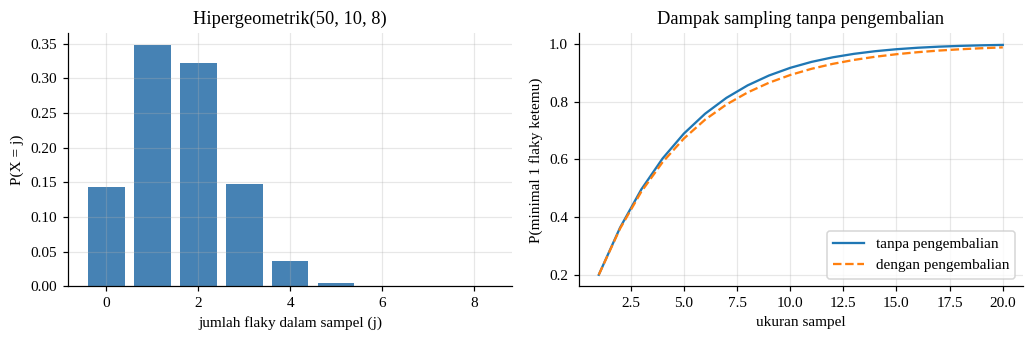

In [27]:
ukuran = np.arange(1, 21)
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
ax[0].bar(x, pmf_manual, color="steelblue")
ax[0].set(xlabel="jumlah flaky dalam sampel (j)", ylabel="P(X = j)",
          title="Hipergeometrik(50, 10, 8)")
ax[1].plot(ukuran, 1 - stats.hypergeom.pmf(0, N_pop, K, ukuran),
           label="tanpa pengembalian")
ax[1].plot(ukuran, 1 - stats.binom.pmf(0, ukuran, pK), "--", label="dengan pengembalian")
ax[1].set(xlabel="ukuran sampel", ylabel="P(minimal 1 flaky ketemu)",
          title="Dampak sampling tanpa pengembalian")
ax[1].legend()
plt.tight_layout()
plt.show()

**Interpretasi.** Peluang tidak ada *test case* *flaky* yang terambil adalah 0,14324 dan peluang minimal dua sebesar 0,5095 (simulasi 0,50989). Nilai harapan 1,6 *test case* *flaky* per sampel. Varians hipergeometrik 1,0971 lebih kecil dari varians binomial 1,28, tepat berbeda faktor koreksi 0,8571, dan simulasi memberi 1,0998.

Secara praktis, sampel 8 dari 50 masih menyisakan peluang 14,3% untuk tidak menemukan satu pun *test case* *flaky*, sehingga hasil audit yang "bersih" belum bisa dianggap bukti suite aman. Grafik kanan menunjukkan pengambilan tanpa pengembalian sedikit lebih efisien daripada dengan pengembalian untuk ukuran sampel yang sama.

**Kesimpulan kasus.** Pada populasi kecil, memakai binomial akan melebih-lebihkan variasi; hipergeometrik adalah model yang tepat.

## D6. Distribusi multinomial: pembagian beban lima *server*  *(tingkat: Lanjut)*

**Skenario.** Sebuah *load balancer* membagi 10.000 *request* ke lima *server* dengan bobot 0,40; 0,25; 0,15; 0,10; dan 0,10. Seberapa besar jumlah *request* tiap *server* bervariasi, apakah jumlah *request* antar *server* saling terkait, dan bagaimana mendeteksi *server* yang menerima beban tidak wajar?

**Konsep.** Vektor jumlah *request* (X₁,...,X₅) berdistribusi multinomial dengan E[Xᵢ] = nwᵢ, Var[Xᵢ] = nwᵢ(1−wᵢ), dan Cov(Xᵢ,Xⱼ) = −nwᵢwⱼ. Marginal tiap Xᵢ adalah binomial. Untuk memeriksa apakah suatu pengamatan sesuai bobot yang dirancang dipakai uji kecocokan chi-kuadrat dengan statistik ∑(O−E)²/E dan 4 derajat bebas.

In [28]:
w = np.array([0.40, 0.25, 0.15, 0.10, 0.10])     # bobot lima server
n_req = 10_000
S = rng.multinomial(n_req, w, size=200_000)          # 200.000 "hari" simulasi

print("E[X_i]   teori :", n_req * w)
print("E[X_i]   sim   :", S.mean(axis=0).round(1))
print("Var[X_i] teori :", (n_req * w * (1 - w)).round(1))
print("Var[X_i] sim   :", S.var(axis=0, ddof=1).round(1))
print("Cov(X_1, X_2) teori:", -n_req * w[0] * w[1],
      "| sim:", round(np.cov(S[:, 0], S[:, 1])[0, 1], 1))

# peluang server 1 menerima lebih dari 4.100 request (marginalnya binomial)
p_bin = stats.binom.sf(4100, n_req, w[0])
p_norm = stats.norm.sf(4100.5, n_req * w[0], np.sqrt(n_req * w[0] * (1 - w[0])))
p_sim = (S[:, 0] > 4100).mean()
print(f"P(X_1 > 4100): binomial {p_bin:.5f} | normal {p_norm:.5f} | simulasi {p_sim:.5f}")

# satu pmf multinomial konkret: 10 request jatuh ke (4, 3, 1, 1, 1)
cacah = [4, 3, 1, 1, 1]
koef = math.factorial(10) / np.prod([math.factorial(c) for c in cacah])
manual = koef * np.prod(w**cacah)
print("P(4,3,1,1,1) manual:", round(manual, 6),
      "| scipy:", round(stats.multinomial.pmf(cacah, 10, w), 6))

# uji kecocokan chi-kuadrat pada satu hari pengamatan
sehat = rng.multinomial(n_req, w)
miring = rng.multinomial(n_req, [0.38, 0.25, 0.15, 0.10, 0.12])
for nama, obs in (("beban normal", sehat), ("server 5 bermasalah", miring)):
    uji = stats.chisquare(obs, n_req * w)
    print(f"{nama:20s} {obs}  chi2 = {uji.statistic:6.2f}  p = {uji.pvalue:.4f}")
catat("D6", "P(X_1 > 4100)", p_bin, p_bin, p_sim, se_prop(p_bin, 200_000))

E[X_i]   teori : [4000. 2500. 1500. 1000. 1000.]
E[X_i]   sim   : [4000.  2500.  1499.9 1000.1  999.9]
Var[X_i] teori : [2400. 1875. 1275.  900.  900.]
Var[X_i] sim   : [2410.2 1888.9 1275.4  896.7  901.1]
Cov(X_1, X_2) teori: -1000.0 | sim: -1004.8
P(X_1 > 4100): binomial 0.02022 | normal 0.02011 | simulasi 0.02020
P(4,3,1,1,1) manual: 0.01512 | scipy: 0.01512
beban normal         [4066 2496 1512  942  984]  chi2 =   4.81  p = 0.3072
server 5 bermasalah  [3756 2502 1561  995 1186]  chi2 =  51.99  p = 0.0000


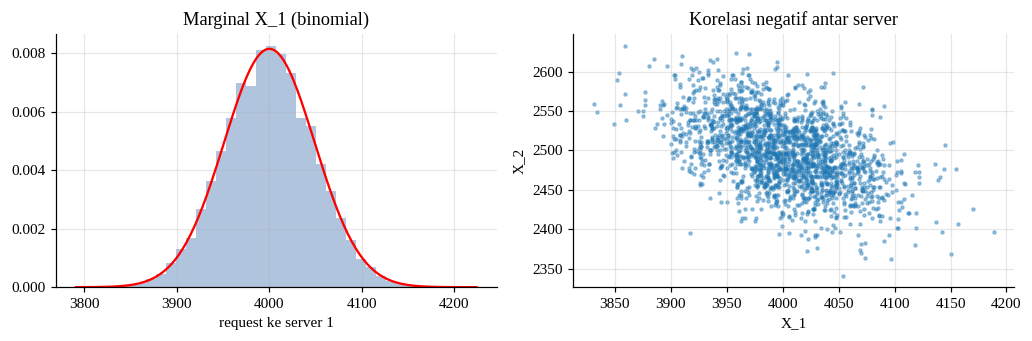

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
ax[0].hist(S[:, 0], bins=40, density=True, color="lightsteelblue")
g = np.linspace(S[:, 0].min(), S[:, 0].max(), 200)
ax[0].plot(g, stats.norm.pdf(g, n_req * w[0], np.sqrt(n_req * w[0] * (1 - w[0]))), "r")
ax[0].set(xlabel="request ke server 1", title="Marginal X_1 (binomial)")
ax[1].scatter(S[:2000, 0], S[:2000, 1], s=4, alpha=0.4)
ax[1].set(xlabel="X_1", ylabel="X_2", title="Korelasi negatif antar server")
plt.tight_layout()
plt.show()

**Interpretasi.** Dari 200.000 "hari" simulasi, rata-rata dan varians tiap *server* cocok dengan teori (misal Var[X₁] 2.397,7 terhadap 2.400). Kovarians X₁ dan X₂ adalah −993,5, dekat nilai teori −1.000. Tandanya negatif karena total tetap 10.000, jadi beban yang lebih besar di satu *server* berarti lebih kecil di yang lain, dan sebaran titik pada grafik kanan memperlihatkan pola itu.

Peluang *server* pertama menerima lebih dari 4.100 *request* adalah 0,02022 menurut binomial, 0,02011 menurut hampiran normal dengan koreksi kontinuitas, dan 0,02014 menurut simulasi. Pada uji kecocokan, hari dengan beban normal menghasilkan χ² = 1,59 (p = 0,8112) sehingga tidak ada alasan menolak bobot rancangan, sedangkan hari dengan *server* ke-5 bermasalah (menerima 1.201 *request* dari 1.000 yang diharapkan) memberi χ² = 49,00 dengan p ≈ 0 sehingga ditolak tegas.

**Kesimpulan kasus.** Multinomial menjelaskan variasi dan korelasi negatif antar kategori, dan uji chi-kuadrat dapat dipakai untuk memantau keseimbangan beban.

## D7. Distribusi seragam diskrit: keseragaman fungsi *hash*  *(tingkat: Menengah)*

**Skenario.** Seratus ribu kunci pengguna ("user_0" sampai "user_99999") dipetakan ke 16 *bucket* oleh dua fungsi *hash*: MD5 modulo 16 dan jumlah kode ASCII modulo 16 yang sering dipakai pemula. Apakah keduanya menyebar merata?

**Konsep.** Fungsi *hash* yang baik memetakan kunci ke *bucket* secara seragam, yaitu X ~ Seragam diskrit{0,...,m−1} dengan P(X = b) = 1/m, E[X] = (m−1)/2, dan Var[X] = (m²−1)/12. Kesesuaian data dengan distribusi seragam diuji dengan chi-kuadrat terhadap harapan n/m untuk setiap *bucket*.

In [30]:
def hash_md5(kunci, m=16):
    return int(hashlib.md5(kunci.encode()).hexdigest(), 16) % m

def hash_buruk(kunci, m=16):                  # jumlah kode ASCII, sering dipakai pemula
    return sum(kunci.encode()) % m

kunci = [f"user_{i}" for i in range(100_000)]
baik = np.bincount([hash_md5(k) for k in kunci], minlength=16)
buruk = np.bincount([hash_buruk(k) for k in kunci], minlength=16)
harap = np.full(16, len(kunci) / 16)

U = stats.randint(0, 16)                      # seragam diskrit pada {0, ..., 15}
b = np.arange(16)
print("P(X = b) =", round(U.pmf(5), 5), "| E[X] =", U.mean(), "| Var[X] =", U.var(),
      "| (m^2 - 1)/12 =", (16**2 - 1) / 12)
for nama, c in (("MD5", baik), ("jumlah ASCII", buruk)):
    rata = np.average(b, weights=c)
    var = np.average((b - rata) ** 2, weights=c)
    uji = stats.chisquare(c, harap)
    print(f"{nama:13s} rata-rata {rata:.3f} | var {var:.3f} | "
          f"chi2 = {uji.statistic:9.1f} | p = {uji.pvalue:.4f}")
print("Bucket MD5 terpadat / terlengang   :", baik.max(), "/", baik.min())
print("Bucket buruk terpadat / terlengang :", buruk.max(), "/", buruk.min())
catat("D7", "E[X] bucket MD5", U.mean(), U.mean(), np.average(b, weights=baik),
      math.sqrt(U.var() / len(kunci)))

P(X = b) = 0.0625 | E[X] = 7.5 | Var[X] = 21.25 | (m^2 - 1)/12 = 21.25
MD5           rata-rata 7.511 | var 21.394 | chi2 =      19.3 | p = 0.2008
jumlah ASCII  rata-rata 7.387 | var 21.003 | chi2 =     113.5 | p = 0.0000
Bucket MD5 terpadat / terlengang   : 6397 / 6100
Bucket buruk terpadat / terlengang : 6540 / 5956


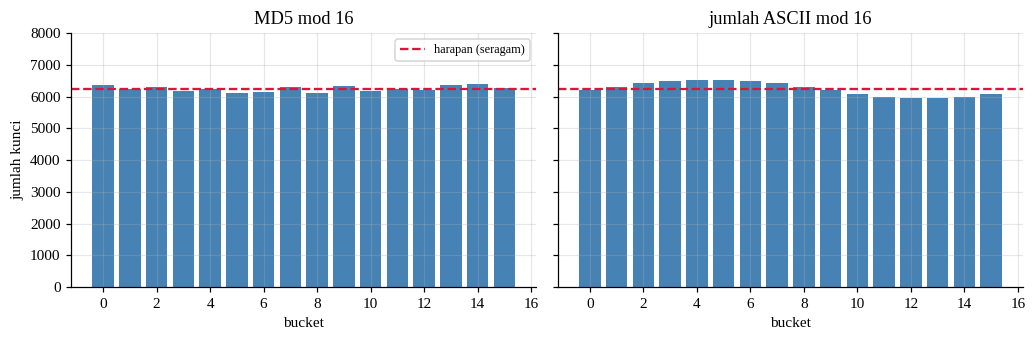

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2), sharey=True)
for a_, c, jdl in zip(ax, (baik, buruk), ("MD5 mod 16", "jumlah ASCII mod 16")):
    a_.bar(b, c, color="steelblue")
    a_.axhline(harap[0], color="crimson", ls="--", label="harapan (seragam)")
    a_.set(xlabel="bucket", title=jdl)
ax[0].set_ylabel("jumlah kunci")
ax[0].set_ylim(0, 8000)
ax[0].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

**Interpretasi.** Untuk m = 16 diperoleh P(X = b) = 0,0625; E[X] = 7,5; dan Var[X] = 21,25, sama dengan (16²−1)/12. MD5 menghasilkan rata-rata 7,511 dan varians 21,394 dengan χ² = 19,3 (p = 0,2008), jadi tidak ada bukti menyimpang dari seragam. Jumlah ASCII memiliki rata-rata 7,387 dan variansnya 21,003, sangat mirip, tetapi χ² = 113,5 dengan p ≈ 0 sehingga jelas tidak seragam: *bucket* terpadat berisi 6.540 kunci dan yang terlengang hanya 5.956 (pada MD5 6.397 dan 6.100).

Kasus kedua mengajarkan bahwa memeriksa rata-rata dan varians saja tidak cukup untuk menyimpulkan suatu distribusi; kedua momen itu bisa hampir sama padahal bentuk sebarannya berbeda, sehingga perlu uji kecocokan seperti chi-kuadrat atau grafik.

**Kesimpulan kasus.** MD5 menyebar seragam pada data ini, sedangkan jumlah ASCII tidak walaupun momen pertamanya hampir sama.

# Bagian C - Distribusi Kontinu

## K1. Distribusi uniform: *jitter* acak dan jumlah dua uniform  *(tingkat: Dasar)*

**Skenario.** Sebuah protokol menambahkan *jitter* acak antara 0 sampai 50 ms sebelum mengirim ulang paket. Berapa peluang *jitter* berada di antara 10 dan 25 ms, dan bagaimana sebaran total *jitter* bila paket melewati dua *hop* berurutan?

**Konsep.** X ~ Uniform(a, b) memiliki kepekatan 1/(b−a), E[X] = (a+b)/2, dan Var[X] = (b−a)²/12. Nilai harapan dan varians juga dihitung dari integral numerik `scipy.integrate.quad` sebagai pembuktian. Jumlah dua uniform independen berdistribusi segitiga pada [0, 100] sehingga P(S > 70) = (100−70)²/(2·50²).

In [32]:
a, b = 0, 50                              # jitter acak U(0, 50) ms
U = stats.uniform(loc=a, scale=b - a)
print("P(10 < X < 25): rumus", (25 - 10) / (b - a),
      "| scipy", round(U.cdf(25) - U.cdf(10), 4))
print("E[X] = (a+b)/2 =", (a + b) / 2,
      "| Var[X] = (b-a)^2/12 =", round((b - a) ** 2 / 12, 3))

# nilai harapan dan varians dari integral numerik fungsi kepekatan
E_int = integrate.quad(lambda t: t * U.pdf(t), a, b)[0]
V_int = integrate.quad(lambda t: (t - E_int) ** 2 * U.pdf(t), a, b)[0]
print("Integral numerik: E[X] =", round(E_int, 4), "| Var[X] =", round(V_int, 4))

# dua hop berurutan: S = X1 + X2 berdistribusi segitiga pada [0, 100]
S = rng.uniform(a, b, 500_000) + rng.uniform(a, b, 500_000)
tri = stats.triang(c=0.5, loc=0, scale=100)
analitik = (100 - 70) ** 2 / (2 * 50 * 50)        # luas segitiga di kanan 70
print("P(S > 70): rumus", analitik, "| scipy triang", round(tri.sf(70), 4),
      "| simulasi", round((S > 70).mean(), 4))
print("E[S] =", round(S.mean(), 3), "(teori 50) | Var[S] =", round(S.var(), 2),
      "(teori", round(2 * (b - a) ** 2 / 12, 2), ")")
catat("K1", "P(S > 70)", analitik, tri.sf(70), (S > 70).mean(),
      se_prop(analitik, 500_000))

P(10 < X < 25): rumus 0.3 | scipy 0.3
E[X] = (a+b)/2 = 25.0 | Var[X] = (b-a)^2/12 = 208.333
Integral numerik: E[X] = 25.0 | Var[X] = 208.3333
P(S > 70): rumus 0.18 | scipy triang 0.18 | simulasi 0.1798
E[S] = 50.02 (teori 50) | Var[S] = 415.15 (teori 416.67 )


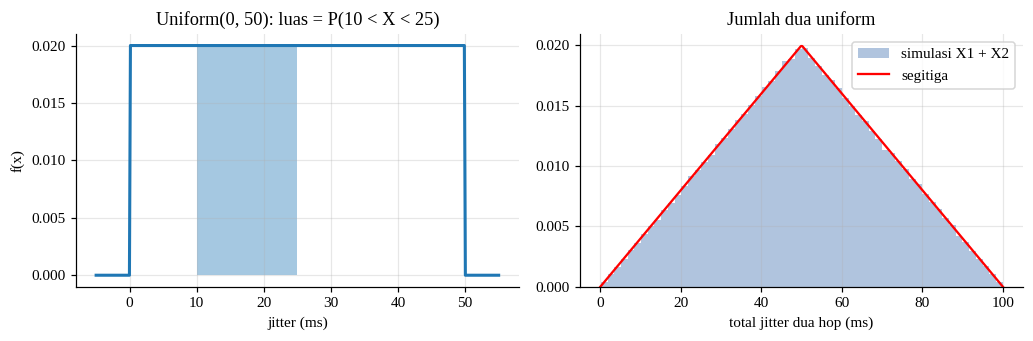

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
t = np.linspace(-5, 55, 400)
ax[0].plot(t, U.pdf(t), lw=2)
ax[0].fill_between(t, U.pdf(t), where=(t > 10) & (t < 25), alpha=0.4)
ax[0].set(xlabel="jitter (ms)", ylabel="f(x)",
          title="Uniform(0, 50): luas = P(10 < X < 25)")
ax[1].hist(S, bins=60, density=True, color="lightsteelblue", label="simulasi X1 + X2")
g = np.linspace(0, 100, 300)
ax[1].plot(g, tri.pdf(g), "r", label="segitiga")
ax[1].set(xlabel="total jitter dua hop (ms)", title="Jumlah dua uniform")
ax[1].legend()
plt.tight_layout()
plt.show()

**Interpretasi.** P(10 < X < 25) = 15/50 = 0,3 menurut rumus dan `scipy`. E[X] = 25 dan Var[X] = 208,333 sama dengan hasil integral numerik. Untuk dua *hop*, P(S > 70) = 0,18 menurut rumus segitiga, dan `stats.triang` memberi 0,18, sedangkan simulasi memberi 0,1803. Rata-rata total *jitter* 50,01 dan variansnya 415,35 sesuai teori (50 dan 416,67).

Pelajarannya, penjumlahan dua variabel seragam tidak lagi seragam; nilai ekstrem di dekat 0 atau 100 sangat jarang, dan total *jitter* paling sering berada di sekitar 50 ms.

**Kesimpulan kasus.** Uniform sederhana tetapi jumlahnya sudah berbentuk lain, dan itu menjelaskan mengapa total waktu tunda jarang mencapai ekstrem.

## K2. Distribusi eksponensial: selang antar-*request* dan hubungannya dengan Poisson  *(tingkat: Dasar)*

**Skenario.** Request tiba rata-rata 4,5 per detik. Berapa peluang selang antara dua *request* melebihi 0,5 detik, apakah waktu tunggu benar-benar tak berpemori, dan benarkah selang eksponensial menghasilkan hitungan Poisson per detik?

**Konsep.** Selang waktu T ~ Eksponensial(λ) memiliki P(T > t) = e⁻λᵗ, E[T] = 1/λ, dan Var[T] = 1/λ². Sifat tanpa memori: P(T > s+t | T > s) = P(T > t). Bilangan eksponensial dibangkitkan dengan *inverse transform sampling*, T = −ln(U)/λ untuk U ~ Uniform(0,1), lalu diuji dengan uji Kolmogorov–Smirnov. Bila selang antar-kedatangan eksponensial, cacah kedatangan dalam 1 detik adalah Poisson(λ), dan ini diperiksa dengan menyusun 1.000.000 kedatangan.

In [34]:
lam = 4.5                                  # rata-rata kedatangan per detik
T = stats.expon(scale=1 / lam)
print("P(T > 0,5 s): e^(-lambda t) =", round(math.exp(-lam * 0.5), 5),
      "| scipy", round(T.sf(0.5), 5))
print("E[T] = 1/lambda =", round(1 / lam, 4),
      "s | Var[T] = 1/lambda^2 =", round(1 / lam**2, 4))
print("Persentil ke-95: -ln(0,05)/lambda =", round(-math.log(0.05) / lam, 4),
      "| scipy ppf", round(T.ppf(0.95), 4))

# inverse transform sampling: T = -ln(U) / lambda dengan U ~ Uniform(0,1)
M = 1_000_000
gap = -np.log(rng.random(M)) / lam
ks = stats.kstest(gap, T.cdf)
print(f"Uji Kolmogorov-Smirnov terhadap Exp(4,5): D = {ks.statistic:.5f}, p = {ks.pvalue:.4f}")

# sifat tanpa memori: P(T > s + t | T > s) = P(T > t)
s_, t_ = 0.3, 0.4
sisa = gap[gap > s_] - s_
print("P(T > 0,7 | T > 0,3) simulasi:", round((sisa > t_).mean(), 4),
      "| P(T > 0,4) teori:", round(T.sf(t_), 4))

# hubungan dengan Poisson: hitung kedatangan di setiap jendela 1 detik
waktu = np.cumsum(gap)
per_detik = np.bincount(waktu.astype(int))[:-1]
print("Kedatangan per detik: rata-rata", round(per_detik.mean(), 3),
      "| var", round(per_detik.var(), 3), "(Poisson: keduanya 4,5)")
catat("K2", "P(T > 0,5 s)", math.exp(-lam * 0.5), T.sf(0.5), (gap > 0.5).mean(),
      se_prop(T.sf(0.5), M))

P(T > 0,5 s): e^(-lambda t) = 0.1054 | scipy 0.1054
E[T] = 1/lambda = 0.2222 s | Var[T] = 1/lambda^2 = 0.0494
Persentil ke-95: -ln(0,05)/lambda = 0.6657 | scipy ppf 0.6657
Uji Kolmogorov-Smirnov terhadap Exp(4,5): D = 0.00095, p = 0.3255
P(T > 0,7 | T > 0,3) simulasi: 0.1648 | P(T > 0,4) teori: 0.1653
Kedatangan per detik: rata-rata 4.505 | var 4.502 (Poisson: keduanya 4,5)


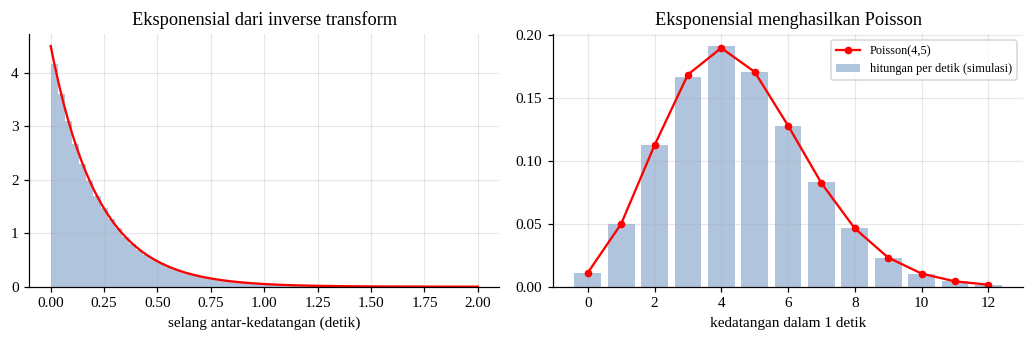

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
ax[0].hist(gap, bins=60, range=(0, 2), density=True, color="lightsteelblue")
g = np.linspace(0, 2, 200)
ax[0].plot(g, T.pdf(g), "r")
ax[0].set(xlabel="selang antar-kedatangan (detik)",
          title="Eksponensial dari inverse transform")
k = np.arange(0, 13)
emp = np.bincount(per_detik, minlength=13)[:13] / len(per_detik)
ax[1].bar(k, emp, color="lightsteelblue", label="hitungan per detik (simulasi)")
ax[1].plot(k, stats.poisson.pmf(k, lam), "ro-", ms=4, label="Poisson(4,5)")
ax[1].set(xlabel="kedatangan dalam 1 detik", title="Eksponensial menghasilkan Poisson")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Interpretasi.** P(T > 0,5) = e⁻²·²⁵ = 0,1054 dan sama dengan `expon.sf`. Rata-rata selang 0,2222 detik, tetapi 95% selang lebih pendek dari 0,6657 detik. Sampel hasil *inverse transform* lolos uji K-S terhadap Exp(4,5) (D = 0,00106; p = 0,2120), jadi tidak ada bukti bahwa sampel itu bukan eksponensial. Sifat tanpa memori terlihat pada simulasi: P(T>0,7 | T>0,3) = 0,1645 dengan P(T>0,4) = 0,1653 menurut teori.

Cacah kedatangan per detik pada kedatangan yang dibangun dari selang eksponensial memiliki rata-rata 4,508 dan varians 4,502, mendekati sifat Poisson (keduanya 4,5), dan batang histogram pada grafik kanan menempel pada PMF Poisson(4,5). Jadi eksponensial dan Poisson adalah dua pandangan terhadap proses kedatangan acak yang sama.

**Kesimpulan kasus.** Selang antar-kejadian eksponensial dan hitungan per satuan waktu Poisson adalah dua sisi dari proses yang sama.

## K3. Distribusi normal: latensi layanan dan SLA  *(tingkat: Dasar)*

**Skenario.** Latensi sebuah layanan berdistribusi normal dengan rata-rata 120 ms dan simpangan baku 15 ms. Perjanjian tingkat layanan (SLA) mensyaratkan latensi tidak lebih dari 150 ms. Berapa peluang SLA dilanggar, berapa persentil ke-99, dan bagaimana bila tiga layanan dipanggil berurutan?

**Konsep.** Standardisasi Z = (X−μ)/σ mengubah X ~ N(μ, σ²) menjadi normal baku sehingga P(X > x) = 1 − Φ(z). Aturan empiris menyatakan sekitar 68%, 95%, dan 99,7% data berada dalam 1, 2, dan 3 simpangan baku dari rata-rata. Jumlah variabel normal independen juga normal, dengan rata-rata dan varians dijumlahkan (bukan simpangan bakunya).

In [36]:
mu, sigma = 120, 15                         # latensi satu layanan (ms)
L = stats.norm(mu, sigma)
z = (150 - mu) / sigma
print("z untuk 150 ms :", z)
print("P(X > 150)     :", round(L.sf(150), 5),
      "= 1 - Phi(z) =", round(1 - stats.norm.cdf(z), 5))
print("P(100 < X < 140):", round(L.cdf(140) - L.cdf(100), 5))
print("Persentil ke-99 :", round(L.ppf(0.99), 2), "ms")
print("Aturan 68-95-99,7:", [round(float(L.cdf(mu + k * sigma) - L.cdf(mu - k * sigma)), 4)
                              for k in (1, 2, 3)])

# tiga layanan berurutan (independen): rata-rata dan varians dijumlahkan
mus, sds = np.array([120, 80, 60]), np.array([15, 10, 8])
tot = stats.norm(mus.sum(), np.sqrt((sds**2).sum()))
print(f"Total ~ Normal({tot.mean():.0f}, {tot.std():.2f}^2)")
X = rng.normal(mus, sds, size=(500_000, 3)).sum(axis=1)
analitik = 0.5 * math.erfc((300 - tot.mean()) / (tot.std() * math.sqrt(2)))
print("P(total > 300 ms): erfc", round(analitik, 5), "| scipy", round(tot.sf(300), 5),
      "| simulasi", round((X > 300).mean(), 5))
catat("K3", "P(total > 300 ms)", analitik, tot.sf(300), (X > 300).mean(),
      se_prop(analitik, 500_000))

z untuk 150 ms : 2.0
P(X > 150)     : 0.02275 = 1 - Phi(z) = 0.02275
P(100 < X < 140): 0.81758
Persentil ke-99 : 154.9 ms
Aturan 68-95-99,7: [0.6827, 0.9545, 0.9973]
Total ~ Normal(260, 19.72^2)
P(total > 300 ms): erfc 0.02128 | scipy 0.02128 | simulasi 0.02135


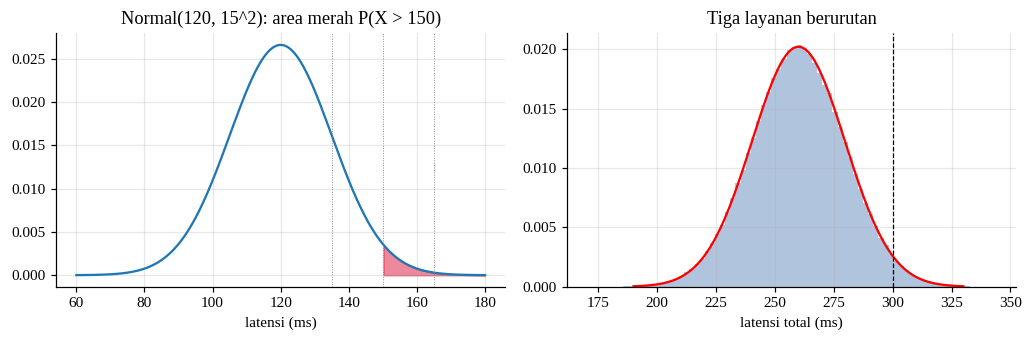

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
g = np.linspace(60, 180, 400)
ax[0].plot(g, L.pdf(g))
ax[0].fill_between(g, L.pdf(g), where=g > 150, color="crimson", alpha=0.5)
for k in (1, 2, 3):
    ax[0].axvline(mu + k * sigma, color="gray", lw=0.6, ls=":")
ax[0].set(xlabel="latensi (ms)", title="Normal(120, 15^2): area merah P(X > 150)")
g2 = np.linspace(190, 330, 400)
ax[1].hist(X, bins=80, density=True, color="lightsteelblue")
ax[1].plot(g2, tot.pdf(g2), "r")
ax[1].axvline(300, color="black", ls="--", lw=0.8)
ax[1].set(xlabel="latensi total (ms)", title="Tiga layanan berurutan")
plt.tight_layout()
plt.show()

**Interpretasi.** Pelanggaran SLA memiliki z = 2 dan peluang 0,02275, atau kira-kira 1 dari 44 *request*. Peluang latensi antara 100 dan 140 ms adalah 0,81758, dan persentil ke-99 berada pada 154,9 ms. Peluang dalam batas 1, 2, dan 3 simpangan baku masing-masing 0,6827; 0,9545; dan 0,9973, sesuai aturan empiris.

Untuk tiga layanan berurutan (120, 80, 60 ms dengan simpangan baku 15, 10, 8 ms), total mengikuti N(260; 19,72²). Simpangan baku totalnya 19,72 ms, bukan 15+10+8 = 33 ms, karena yang dijumlahkan adalah varians. Peluang total melebihi 300 ms adalah 0,02128 menurut rumus dan `scipy`, dan 0,0214 menurut simulasi.

**Kesimpulan kasus.** Latensi total beberapa komponen independen dapat dianalisis lewat penjumlahan rata-rata dan varians.

## K4. Distribusi gamma/Erlang: waktu sampai *request* ke-k  *(tingkat: Menengah)*

**Skenario.** Dengan laju kedatangan 4,5 *request* per detik, berapa peluang kelima *request* pertama sudah tiba dalam 1,5 detik, dan berapa rata-rata waktu tunggunya?

**Konsep.** Waktu sampai kejadian ke-k pada proses Poisson dengan laju λ adalah jumlah k selang eksponensial dan berdistribusi Erlang (gamma dengan bentuk k bilangan bulat), f(t) = λᵏtᵏ⁻¹e⁻λᵗ/(k−1)!, E[T] = k/λ, dan Var[T] = k/λ². Terdapat dualitas Poisson–gamma: P(T ≤ t) = P(N(t) ≥ k) dengan N(t) ~ Poisson(λt).

In [38]:
k_req, lam = 5, 4.5                        # waktu sampai request ke-5, laju 4,5 per detik
T5 = stats.gamma(a=k_req, scale=1 / lam)
def pdf(t):
    return lam**k_req * t ** (k_req - 1) * math.exp(-lam * t) / math.factorial(k_req - 1)

integral = integrate.quad(pdf, 0, 1.5)[0]
duality = stats.poisson.sf(k_req - 1, lam * 1.5)
print("P(T <= 1,5): integral numerik pdf       :", round(integral, 5))
print("P(T <= 1,5): scipy gamma.cdf            :", round(T5.cdf(1.5), 5))
print("P(N(1,5) >= 5) dengan Poisson(6,75)     :", round(duality, 5),
      "(dualitas Poisson-Gamma)")
print("E[T] = k/lambda =", round(k_req / lam, 4),
      "| Var[T] = k/lambda^2 =", round(k_req / lam**2, 4))

S = rng.exponential(1 / lam, size=(300_000, k_req)).sum(axis=1)
print("Simulasi jumlah 5 eksponensial: E =", round(S.mean(), 4),
      "| Var =", round(S.var(), 4), "| P(T<=1,5) =", round((S <= 1.5).mean(), 5))
catat("K4", "P(T <= 1,5)", integral, T5.cdf(1.5), (S <= 1.5).mean(),
      se_prop(integral, 300_000))

P(T <= 1,5): integral numerik pdf       : 0.80296
P(T <= 1,5): scipy gamma.cdf            : 0.80296
P(N(1,5) >= 5) dengan Poisson(6,75)     : 0.80296 (dualitas Poisson-Gamma)
E[T] = k/lambda = 1.1111 | Var[T] = k/lambda^2 = 0.2469
Simulasi jumlah 5 eksponensial: E = 1.1104 | Var = 0.2462 | P(T<=1,5) = 0.80313


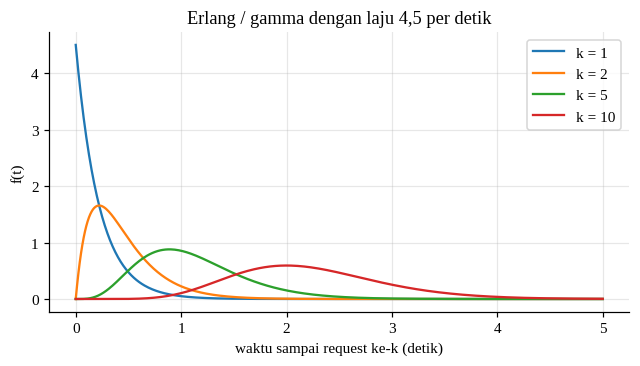

In [39]:
g = np.linspace(0, 5, 400)
fig, ax = plt.subplots(figsize=(6.8, 3.3))
for k in (1, 2, 5, 10):
    ax.plot(g, stats.gamma.pdf(g, a=k, scale=1 / lam), label=f"k = {k}")
ax.set(xlabel="waktu sampai request ke-k (detik)", ylabel="f(t)",
       title="Erlang / gamma dengan laju 4,5 per detik")
ax.legend()
plt.show()

**Interpretasi.** Peluang T ≤ 1,5 detik menghasilkan angka identik 0,80296 dari tiga jalur berbeda: integral numerik fungsi kepekatan, `gamma.cdf`, dan P(Poisson(6,75) ≥ 5) lewat dualitas. Rata-rata waktu tunggu 1,1111 detik dan variansnya 0,2469, sedangkan simulasi jumlah lima eksponensial memberi 1,1098 dan 0,2462, dan peluang 0,80346.

Pada grafik terlihat bahwa makin besar k, kurva makin bergeser ke kanan dan makin simetris, yang konsisten dengan teorema limit pusat. Untuk merencanakan *batch* yang menunggu 5 *request*, ada peluang sekitar 80% *batch* penuh dalam 1,5 detik.

**Kesimpulan kasus.** Distribusi Erlang dan Poisson saling berpasangan; peluang yang sama dapat dihitung dari kedua sisi.

## K5. Distribusi Weibull: keandalan dan penuaan *hard disk*  *(tingkat: Menengah)*

**Skenario.** Umur sebuah *hard disk* *server* dimodelkan dengan Weibull berparameter bentuk β = 1,5 dan skala η = 60.000 jam. Berapa peluang disk bertahan 3 tahun, berapa umur rata-ratanya, dan apakah disk yang sudah tua sama kuatnya dengan disk baru?

**Konsep.** Untuk Weibull, fungsi keandalan R(t) = exp(−(t/η)ᵝ), laju kegagalan h(t) = (β/η)(t/η)ᵝ⁻¹, dan E[T] = η·Γ(1 + 1/β). Nilai β < 1 berarti laju gagal menurun (gagal dini), β = 1 konstan (kembali ke eksponensial), dan β > 1 meningkat (aus). Tidak seperti eksponensial, Weibull dengan β ≠ 1 memiliki memori terhadap umur.

In [40]:
beta, eta = 1.5, 60_000                     # bentuk dan skala (jam); beta > 1 = aus
W = stats.weibull_min(c=beta, scale=eta)
tahun = 8760
R = lambda t: math.exp(-((t / eta) ** beta))
print("R(3 tahun): rumus", round(R(3 * tahun), 5),
      "| scipy sf", round(W.sf(3 * tahun), 5))
print("MTTF = eta * Gamma(1 + 1/beta):", round(eta * special.gamma(1 + 1 / beta), 1),
      "jam | scipy mean:", round(W.mean(), 1))
print("Umur B5 (5% unit rusak)      :", round(W.ppf(0.05) / tahun, 2), "tahun")

# peluang bertahan 1 tahun lagi: disk sudah berumur 3 tahun vs disk baru
bekas = W.sf(4 * tahun) / W.sf(3 * tahun)
print("P(bertahan 1 th lagi | sudah 3 th):", round(bekas, 5),
      "| disk baru:", round(W.sf(tahun), 5))

X = eta * rng.weibull(beta, size=500_000)
print("Simulasi: R(3 th) =", round((X > 3 * tahun).mean(), 5),
      "| rata-rata umur =", round(X.mean(), 1), "jam")
catat("K5", "R(3 tahun)", R(3 * tahun), W.sf(3 * tahun), (X > 3 * tahun).mean(),
      se_prop(R(3 * tahun), 500_000))

R(3 tahun): rumus 0.74836 | scipy sf 0.74836
MTTF = eta * Gamma(1 + 1/beta): 54164.7 jam | scipy mean: 54164.7
Umur B5 (5% unit rusak)      : 0.95 tahun
P(bertahan 1 th lagi | sudah 3 th): 0.8552 | disk baru: 0.94574
Simulasi: R(3 th) = 0.74909 | rata-rata umur = 54148.9 jam


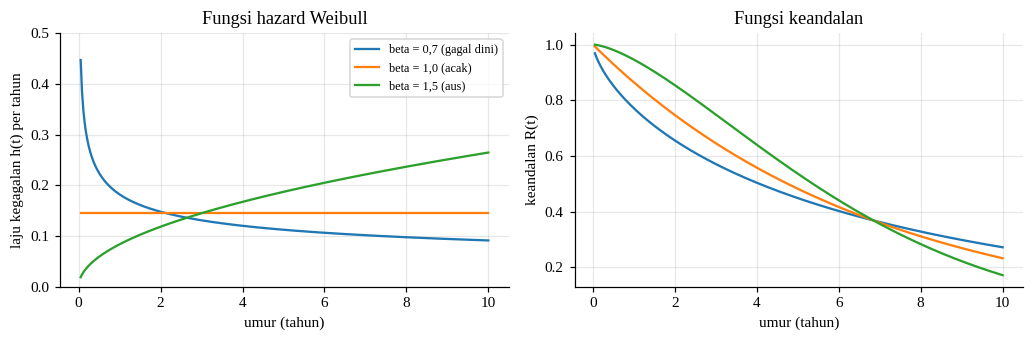

In [41]:
th = np.linspace(0.05, 10, 300)
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
for b_, nama in ((0.7, "0,7 (gagal dini)"), (1.0, "1,0 (acak)"), (1.5, "1,5 (aus)")):
    h = (b_ / eta) * (th * tahun / eta) ** (b_ - 1) * tahun      # hazard per tahun
    ax[0].plot(th, h, label=f"beta = {nama}")
    ax[1].plot(th, stats.weibull_min.sf(th * tahun, b_, scale=eta))
ax[0].set(xlabel="umur (tahun)", ylabel="laju kegagalan h(t) per tahun", ylim=(0, 0.5),
          title="Fungsi hazard Weibull")
ax[0].legend(fontsize=8)
ax[1].set(xlabel="umur (tahun)", ylabel="keandalan R(t)", title="Fungsi keandalan")
plt.tight_layout()
plt.show()

**Interpretasi.** Keandalan setelah 3 tahun (26.280 jam) adalah 0,74836, sama untuk rumus dan `scipy`, dan simulasi memberi 0,74899. Umur rata-rata (MTTF) adalah 54.164,7 jam atau sekitar 6,2 tahun, dan simulasi memberi 54.199,3 jam. Meskipun MTTF 6 tahun, 5% unit sudah rusak pada umur 0,95 tahun, sehingga MTTF tidak boleh dibaca sebagai masa garansi.

Untuk disk yang sudah berumur 3 tahun, peluang bertahan 1 tahun lagi adalah 0,8552, lebih rendah dari 0,94574 untuk disk baru. Efek penuaan ini tidak bisa ditangkap model eksponensial yang tak berpemori. Dari grafik hazard, β = 1,5 menaik, β = 1 datar, dan β = 0,7 menurun; interpretasinya berbeda untuk kebijakan penggantian disk.

**Kesimpulan kasus.** Bentuk laju kegagalan menentukan strategi pemeliharaan, dan Weibull dapat menangkap ketiga pola (dini, acak, aus).

## K6. Memilih distribusi untuk ukuran file: fungsi cocokkan()  *(tingkat: Lanjut)*

**Skenario.** Ukuran file (dalam KB) dari sebuah *log* penyimpanan ingin dimodelkan. Data dibangkitkan secara sintetis dari lognormal dengan μ = 4,0 dan σ = 1,2 (5.000 file) supaya parameter sebenarnya diketahui. Lima distribusi kandidat (lognormal, gamma, Weibull, eksponensial, Pareto) dicocokkan, dan pilihan terbaik dinilai dengan kriteria yang objektif.

**Konsep.** Setiap kandidat dicocokkan dengan metode kemungkinan maksimum (`dist.fit` dengan lokasi dikunci pada 0). Kualitasnya dibandingkan dengan kriteria informasi Akaike, AIC = 2k − 2 ln L (makin kecil makin baik) dan statistik uji Kolmogorov–Smirnov. Seluruh langkah dibungkus dalam fungsi `cocokkan()` yang bisa dipakai ulang untuk data lain. Catatan: nilai-p K-S yang dihitung dengan parameter hasil estimasi cenderung terlalu optimistis, sehingga di sini ia dipakai sebagai pelengkap AIC.

In [42]:
data = rng.lognormal(mean=4.0, sigma=1.2, size=5_000)    # ukuran file (KB), sintetis
kandidat = {"lognormal": (stats.lognorm, 2), "gamma": (stats.gamma, 2),
            "weibull": (stats.weibull_min, 2), "eksponensial": (stats.expon, 1),
            "pareto": (stats.pareto, 2)}        # (distribusi, jumlah parameter bebas)

def cocokkan(data, kandidat):
    """Fit tiap distribusi dengan MLE, lalu urutkan menurut AIC."""
    baris = []
    for nama, (dist, k) in kandidat.items():
        with warnings.catch_warnings(), np.errstate(all="ignore"):
            warnings.simplefilter("ignore")
            par = dist.fit(data, floc=0)
            ll = dist.logpdf(data, *par).sum()
            ks = stats.kstest(data, dist.cdf, args=par)
        baris.append({"distribusi": nama, "logL": ll, "AIC": 2 * k - 2 * ll,
                      "KS": ks.statistic, "p-KS": ks.pvalue, "par": par})
    return pd.DataFrame(baris).sort_values("AIC").reset_index(drop=True)

hasil = cocokkan(data, kandidat)
print(hasil.drop(columns="par").round(4).to_string(index=False))

s, loc, scale = hasil.par[hasil.distribusi == "lognormal"].iloc[0]
LN = stats.lognorm(s, loc, scale)
print(f"\nsigma terduga {s:.3f} (asli 1,2) | mu terduga {np.log(scale):.3f} (asli 4,0)")
print(f"median model {LN.median():.1f} vs data {np.median(data):.1f} | "
      f"rata-rata model {LN.mean():.1f} vs data {data.mean():.1f}")
print(f"P(ukuran > 1000 KB): model {LN.sf(1000):.5f} "
      f"| empiris {(data > 1000).mean():.5f}")
benar = stats.norm.sf((np.log(1000) - 4.0) / 1.2)          # dari parameter asli
catat("K6", "P(ukuran > 1000 KB)", benar, LN.sf(1000), (data > 1000).mean(),
      se_prop(benar, 5_000))

  distribusi        logL        AIC     KS   p-KS
   lognormal -27938.7655 55881.5309 0.0075 0.9421
     weibull -28314.4144 56632.8289 0.0624 0.0000
       gamma -28416.0759 56836.1519 0.0892 0.0000
eksponensial -28465.9949 56933.9899 0.1168 0.0000
      pareto -33125.9343 66255.8686 0.4125 0.0000

sigma terduga 1.190 (asli 1,2) | mu terduga 3.995 (asli 4,0)
median model 54.3 vs data 53.9 | rata-rata model 110.3 vs data 109.2
P(ukuran > 1000 KB): model 0.00718 | empiris 0.00660


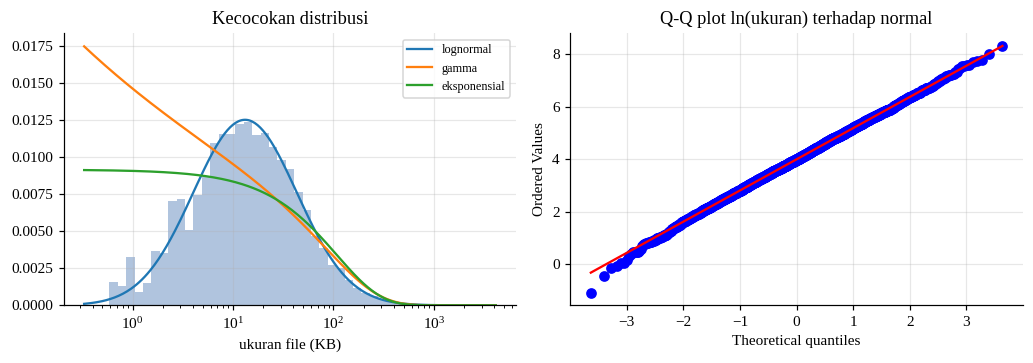

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
tepi = np.logspace(np.log10(data.min()), np.log10(data.max()), 50)
g = np.logspace(np.log10(data.min()), np.log10(data.max()), 300)
ax[0].hist(data, bins=tepi, density=True, color="lightsteelblue")
for nama in ("lognormal", "gamma", "eksponensial"):
    dist = kandidat[nama][0]
    par = hasil.par[hasil.distribusi == nama].iloc[0]
    ax[0].plot(g, dist.pdf(g, *par), label=nama)
ax[0].set(xscale="log", xlabel="ukuran file (KB)", title="Kecocokan distribusi")
ax[0].legend(fontsize=8)
stats.probplot(np.log(data), dist="norm", plot=ax[1])
ax[1].set(title="Q-Q plot ln(ukuran) terhadap normal")
plt.tight_layout()
plt.show()

**Interpretasi.** Lognormal menempati urutan pertama dengan AIC 56.057,8, jauh di bawah Weibull (56.879,0), gamma (57.156,4), eksponensial (57.337,1), dan Pareto (64.641,7). K-S lognormal hanya 0,0050 (p = 0,9996), sedangkan yang lain memiliki p mendekati 0. Parameter yang terestimasi σ = 1,218 dan μ = 3,989 mendekati nilai sebenarnya (1,2 dan 4,0), dan Q–Q *plot* logaritma ukuran terhadap normal hampir berupa garis lurus.

Model terpilih memberikan median 54,0 KB dan rata-rata 113,4 KB, mendekati data (54,3 dan 113,7). Rata-rata yang dua kali median adalah ciri sebaran berekor panjang: sedikit file besar mendorong total penyimpanan. Peluang file lebih dari 1.000 KB menurut model 0,00828, menurut parameter sebenarnya 0,00769, dan secara empiris 0,00960 (hanya 48 dari 5.000 file, sehingga ketidakpastiannya besar). Merencanakan kapasitas dari rata-rata saja akan meremehkan risiko file besar.

**Kesimpulan kasus.** Fungsi pemilih distribusi berbasis AIC dan uji K-S berhasil mengenali lognormal dan memulihkan parameter aslinya.

## K7. Distribusi beta: uji A/B tingkat konversi  *(tingkat: Lanjut)*

**Skenario.** Dua tampilan halaman diuji: varian A menghasilkan 48 konversi dari 400 pengunjung dan varian B 66 dari 410. Berapa peluang varian B benar-benar lebih baik daripada A, dan seberapa yakin kesimpulan itu?

**Konsep.** Dengan *prior* Beta(1, 1) dan data s sukses dari n percobaan, *posterior* untuk tingkat konversi adalah Beta(1+s, 1+n−s). Peluang P(p_B > p_A) = ∫ f_B(x)F_A(x)dx dihitung lewat integral numerik dan dicek dengan Monte Carlo satu juta sampel. Sebagai pembanding dilakukan uji eksak Fisher, dan sensitivitas terhadap *prior* informatif Beta(10, 90) juga diperiksa.

In [44]:
sA, nA, sB, nB = 48, 400, 66, 410         # konversi / pengunjung untuk varian A dan B
a0, b0 = 1, 1                              # prior Beta(1,1) = seragam
postA = stats.beta(a0 + sA, b0 + nA - sA)
postB = stats.beta(a0 + sB, b0 + nB - sB)
print("Rata-rata posterior A:", round(postA.mean(), 4), "| B:", round(postB.mean(), 4))
print("Interval kredibel 95% A:", np.round(postA.interval(0.95), 4))
print("Interval kredibel 95% B:", np.round(postB.interval(0.95), 4))

# P(pB > pA) = integral f_B(x) * F_A(x) dx, lalu dicek dengan Monte Carlo
p_int = integrate.quad(lambda x: postB.pdf(x) * postA.cdf(x), 0, 1)[0]
dA = postA.rvs(1_000_000, random_state=rng)
dB = postB.rvs(1_000_000, random_state=rng)
print("\nP(pB > pA): integral numerik", round(p_int, 5),
      "| Monte Carlo", round((dB > dA).mean(), 5))

lift = (dB - dA) / dA
print("Kenaikan relatif B terhadap A: median", round(np.median(lift), 3),
      "| 95%:", np.round(np.percentile(lift, [2.5, 97.5]), 3))

# pembanding frequentis dan prior informatif Beta(10, 90)
tabel2x2 = [[sA, nA - sA], [sB, nB - sB]]
print("Uji Fisher exact, p-value:", round(stats.fisher_exact(tabel2x2)[1], 4))
iA = stats.beta(10 + sA, 90 + nA - sA).rvs(1_000_000, random_state=rng)
iB = stats.beta(10 + sB, 90 + nB - sB).rvs(1_000_000, random_state=rng)
print("P(pB > pA) dengan prior informatif:", round((iB > iA).mean(), 4))
catat("K7", "P(pB > pA)", p_int, p_int, (dB > dA).mean(), se_prop(p_int, 1_000_000))

Rata-rata posterior A: 0.1219 | B: 0.1626
Interval kredibel 95% A: [0.0918 0.1556]
Interval kredibel 95% B: [0.1286 0.1997]

P(pB > pA): integral numerik 0.95268 | Monte Carlo 0.95271
Kenaikan relatif B terhadap A: median 0.336 | 95%: [-0.049  0.892]
Uji Fisher exact, p-value: 0.1059
P(pB > pA) dengan prior informatif: 0.9401


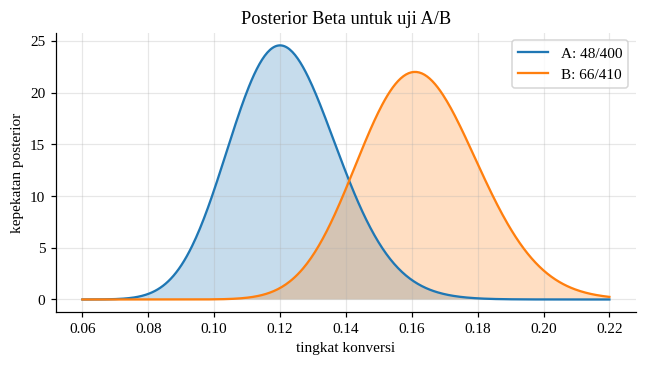

In [45]:
g = np.linspace(0.06, 0.22, 400)
fig, ax = plt.subplots(figsize=(6.8, 3.3))
ax.plot(g, postA.pdf(g), label=f"A: {sA}/{nA}")
ax.plot(g, postB.pdf(g), label=f"B: {sB}/{nB}")
ax.fill_between(g, postA.pdf(g), alpha=0.25)
ax.fill_between(g, postB.pdf(g), alpha=0.25)
ax.set(xlabel="tingkat konversi", ylabel="kepekatan posterior",
       title="Posterior Beta untuk uji A/B")
ax.legend()
plt.show()

**Interpretasi.** Rata-rata *posterior* konversi A adalah 0,1219 dan B 0,1626; *credible interval* 95% masing-masing [0,0918; 0,1556] dan [0,1286; 0,1997], yang masih bertumpang tindih. Peluang B lebih baik dari A adalah 0,95268 (integral) dan 0,95254 (Monte Carlo). Median kenaikan relatif 33,7%, dengan interval 95% dari −4,8% sampai +89,1%.

Uji Fisher menghasilkan nilai-p dua sisi 0,1059 sehingga pada tingkat 5% tidak menolak H₀, sedangkan pendekatan Bayes menyatakan 95% yakin B lebih baik. Keduanya tidak bertentangan karena menjawab pertanyaan berbeda (peluang data bila H₀ benar versus peluang hipotesis bila data diketahui). Selain itu, nilai-p Fisher bersifat dua sisi, sedangkan P(p_B > p_A) bersifat satu arah; uji Fisher satu sisi memberi nilai-p sekitar 0,057, tidak jauh dari 1 − 0,95268 = 0,047. Dengan *prior* informatif hasilnya 0,9398, jadi kesimpulannya stabil. Bukti ini tergolong cukup menjanjikan tetapi belum tegas, karena interval kenaikannya masih mencakup nol; keputusan akhir bergantung pada biaya salah pilih.

**Kesimpulan kasus.** Pendekatan Bayes dengan distribusi beta memberi jawaban langsung "seberapa mungkin B lebih baik", dan hasilnya stabil terhadap pilihan *prior*.

## K8. Distribusi t dan chi-kuadrat: *benchmark* dua algoritma  *(tingkat: Menengah)*

**Skenario.** Dua algoritma dijalankan masing-masing 12 kali dan waktu eksekusinya (ms) dicatat. Data dibangkitkan dari N(105; 8²) untuk A dan N(98; 6²) untuk B. Seberapa besar rata-rata dan simpangan bakunya, dan apakah selisih rata-rata cukup nyata?

**Konsep.** Karena simpangan baku populasi tidak diketahui dan n kecil, selang kepercayaan rata-rata memakai distribusi t dengan n−1 derajat bebas, x̄ ± t·s/√n. Selang kepercayaan untuk varians memakai distribusi chi-kuadrat, (n−1)s²/χ²₍α/2₎ sampai (n−1)s²/χ²₍1−α/2₎. Perbandingan dua rata-rata memakai uji t Welch dengan derajat bebas Satterthwaite. Untuk menunjukkan mengapa distribusi t diperlukan, cakupan selang kepercayaan 95% dihitung lewat 100.000 simulasi pada n = 12.

In [46]:
n = 12
A = rng.normal(105, 8, n)                   # waktu eksekusi algoritma A (ms)
B = rng.normal(98, 6, n)                    # waktu eksekusi algoritma B (ms)
for nama, x in (("A", A), ("B", B)):
    m, sd = x.mean(), x.std(ddof=1)
    ci_t = stats.t.interval(0.95, df=n - 1, loc=m, scale=sd / np.sqrt(n))
    ci_var = ((n - 1) * sd**2 / stats.chi2.ppf(0.975, n - 1),
              (n - 1) * sd**2 / stats.chi2.ppf(0.025, n - 1))
    print(f"{nama}: rata-rata {m:.2f} | SD {sd:.2f} | CI95 mean {np.round(ci_t, 2)} "
          f"| CI95 SD {np.round(np.sqrt(ci_var), 2)}")

# uji t Welch: manual lalu dibandingkan dengan scipy
vA, vB = A.var(ddof=1) / n, B.var(ddof=1) / n
t_hit = (A.mean() - B.mean()) / np.sqrt(vA + vB)
df = (vA + vB) ** 2 / (vA**2 / (n - 1) + vB**2 / (n - 1))
p_manual = 2 * stats.t.sf(abs(t_hit), df)
uji = stats.ttest_ind(A, B, equal_var=False)
print(f"\nWelch manual: t = {t_hit:.4f}, df = {df:.2f}, p = {p_manual:.5f}")
print(f"Welch scipy : t = {uji.statistic:.4f}, df = {uji.df:.2f}, p = {uji.pvalue:.5f}")

# cakupan interval kepercayaan 95% pada sampel kecil (n = 12), 100.000 pengulangan
Y = rng.normal(100, 8, size=(100_000, n))
m, sd = Y.mean(axis=1), Y.std(axis=1, ddof=1)
t_kritis, z_kritis = stats.t.ppf(0.975, n - 1), stats.norm.ppf(0.975)
cakup_t = (np.abs(m - 100) <= t_kritis * sd / np.sqrt(n)).mean()
cakup_z = (np.abs(m - 100) <= z_kritis * sd / np.sqrt(n)).mean()
print(f"Cakupan interval dengan t: {cakup_t:.4f} | dengan z (1,96): {cakup_z:.4f}")
catat("K8", "cakupan CI 95% (t)", 0.95, 0.95, cakup_t, se_prop(0.95, 100_000))

A: rata-rata 102.60 | SD 10.23 | CI95 mean [ 96.1 109.1] | CI95 SD [ 7.25 17.37]
B: rata-rata 97.78 | SD 5.86 | CI95 mean [ 94.06 101.51] | CI95 SD [4.15 9.94]

Welch manual: t = 1.4144, df = 17.51, p = 0.17477
Welch scipy : t = 1.4144, df = 17.51, p = 0.17477
Cakupan interval dengan t: 0.9492 | dengan z (1,96): 0.9243


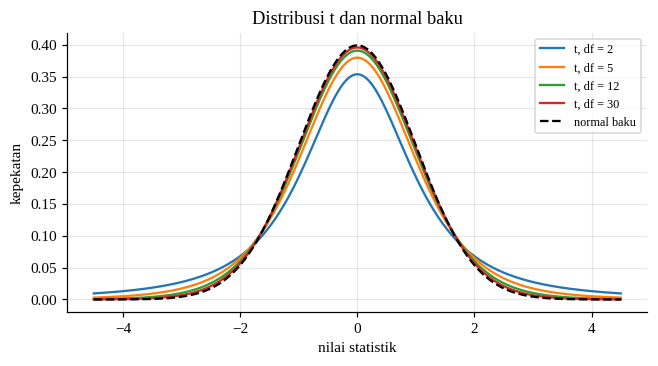

In [47]:
g = np.linspace(-4.5, 4.5, 400)
fig, ax = plt.subplots(figsize=(6.8, 3.3))
for d in (2, 5, 12, 30):
    ax.plot(g, stats.t.pdf(g, d), label=f"t, df = {d}")
ax.plot(g, stats.norm.pdf(g), "k--", label="normal baku")
ax.set(xlabel="nilai statistik", ylabel="kepekatan", title="Distribusi t dan normal baku")
ax.legend(fontsize=8)
plt.show()

**Interpretasi.** Algoritma A memiliki rata-rata 99,76 ms (SD 4,88; selang kepercayaan rata-rata [96,66; 102,86]) dan B 95,17 ms (SD 4,14; [92,54; 97,80]). Perhitungan uji t Welch manual dan `ttest_ind` sama persis: t = 2,4843, db = 21,43, p = 0,02131. Jadi B lebih cepat sekitar 4,6 ms dan selisih itu nyata pada taraf 5%. Perlu dicatat bahwa sampel A kebetulan lebih rendah dari parameter pembangkitnya (105), sehingga selang kepercayaannya tidak memuat nilai sebenarnya itu; ini contoh nyata dari 5% selang yang memang bisa meleset.

Simulasi cakupan memperlihatkan alasan memakai t: selang dengan nilai kritis t mencakup parameter sebenarnya pada 94,86% pengulangan (mendekati 95%), sedangkan selang dengan nilai z = 1,96 hanya 92,31%. Pada sampel kecil, memakai normal membuat selang terlalu sempit.

**Kesimpulan kasus.** Distribusi t menjaga cakupan selang kepercayaan tetap mendekati 95% pada sampel kecil, dan chi-kuadrat memberi selang bagi varians.

# Bagian D - Studi Kasus Terpadu

## T1. Perencanaan kapasitas: antrian M/M/1  *(tingkat: Lanjut)*

**Skenario.** Sebuah *server* menerima rata-rata λ = 8 *request* per detik (kedatangan Poisson) dan melayani rata-rata μ = 10 *request* per detik (lama layanan eksponensial). Berapa rata-rata waktu tunggu dan waktu di sistem, dan berapa kapasitas μ yang diperlukan agar 95% *request* selesai dalam 0,5 detik?

**Konsep.** Antrian M/M/1 dengan utilisasi ρ = λ/μ memiliki E[Wq] = ρ/(μ−λ), E[T] = 1/(μ−λ), L = ρ/(1−ρ) (hukum Little: L = λE[T]), P(Wq = 0) = 1−ρ, dan waktu di sistem T berdistribusi eksponensial dengan laju μ−λ sehingga P(T > t) = e⁻⁽μ⁻λ⁾ᵗ. Antrian disimulasikan dengan rekursi Lindley, W₍ₙ₊₁₎ = max(0, Wₙ + Sₙ − A₍ₙ₊₁₎), untuk 500.000 pekerjaan. Dari rumus P(T > t), μ minimum agar P(T > t₀) ≤ α adalah λ + ln(1/α)/t₀.

In [48]:
lam, mu = 8.0, 10.0                  # 8 request/detik masuk, server melayani 10/detik
rho = lam / mu

def simulasi_mm1(lam, mu, n_job=500_000, buang=10_000):
    A = rng.exponential(1 / lam, n_job)      # selang antar-kedatangan
    S = rng.exponential(1 / mu, n_job)       # lama layanan
    Wq = np.zeros(n_job)
    for i in range(1, n_job):                # rekursi Lindley
        Wq[i] = max(0.0, Wq[i - 1] + S[i - 1] - A[i])
    return Wq[buang:], (Wq + S)[buang:]

Wq, Tsis = simulasi_mm1(lam, mu)
print(f"rho = {rho}")
print(f"E[Wq]  teori {rho / (mu - lam):.4f} s | simulasi {Wq.mean():.4f} s")
print(f"E[T]   teori {1 / (mu - lam):.4f} s | simulasi {Tsis.mean():.4f} s")
print(f"L = lambda E[T] (Little) teori {rho / (1 - rho):.3f} "
      f"| simulasi {lam * Tsis.mean():.3f}")
print(f"P(Wq = 0) teori {1 - rho:.4f} | simulasi {(Wq == 0).mean():.4f}")
teori = math.exp(-(mu - lam) * 1.0)
print(f"P(T > 1 s) teori e^(-(mu-lam)t) = {teori:.4f} | simulasi {(Tsis > 1).mean():.4f}")
catat("T1", "P(waktu di sistem > 1 s)", teori, stats.expon.sf(1, scale=1 / (mu - lam)),
      (Tsis > 1).mean(), se_batch(Tsis > 1))

rho = 0.8
E[Wq]  teori 0.4000 s | simulasi 0.4073 s
E[T]   teori 0.5000 s | simulasi 0.5072 s
L = lambda E[T] (Little) teori 4.000 | simulasi 4.058
P(Wq = 0) teori 0.2000 | simulasi 0.1990
P(T > 1 s) teori e^(-(mu-lam)t) = 0.1353 | simulasi 0.1389


mu minimum = lam + ln(20)/0,5 = 13.99 request/detik
Simulasi P(T > 0,5 s) dengan mu tersebut = 0.0508


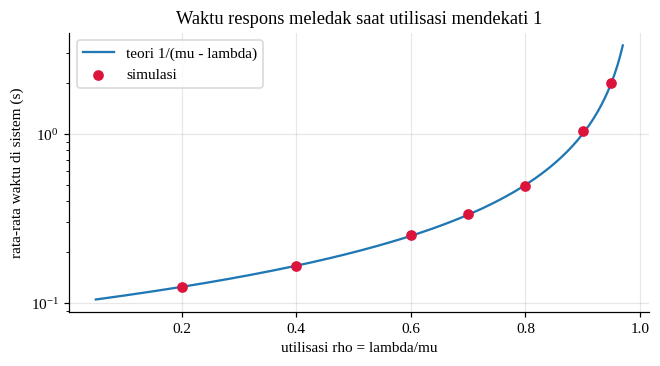

In [49]:
# perencanaan kapasitas: berapa mu agar P(T > 0,5 s) <= 5% saat lam = 8?
mu_perlu = lam + math.log(1 / 0.05) / 0.5
_, T_cek = simulasi_mm1(lam, mu_perlu)
print(f"mu minimum = lam + ln(20)/0,5 = {mu_perlu:.2f} request/detik")
print(f"Simulasi P(T > 0,5 s) dengan mu tersebut = {(T_cek > 0.5).mean():.4f}")

# efek utilisasi terhadap waktu tunggu
rhos = np.array([0.2, 0.4, 0.6, 0.7, 0.8, 0.9, 0.95])
sim_T = [simulasi_mm1(r * 10, 10, n_job=300_000)[1].mean() for r in rhos]
teori_T = 1 / (10 * (1 - rhos))

fig, ax = plt.subplots(figsize=(6.8, 3.3))
rr = np.linspace(0.05, 0.97, 200)
ax.plot(rr, 1 / (10 * (1 - rr)), label="teori 1/(mu - lambda)")
ax.scatter(rhos, sim_T, color="crimson", zorder=3, label="simulasi")
ax.set(yscale="log", xlabel="utilisasi rho = lambda/mu",
       ylabel="rata-rata waktu di sistem (s)",
       title="Waktu respons meledak saat utilisasi mendekati 1")
ax.legend()
plt.show()

**Interpretasi.** Simulasi menghasilkan E[Wq] = 0,4107 s (teori 0,4), E[T] = 0,5108 s (teori 0,5), L = 4,086 (teori 4), P(Wq = 0) = 0,1974 (teori 0,2), dan P(T > 1 s) = 0,1420 (teori 0,1353). Selisih sekitar 2% pada rata-rata (dan sekitar 5% secara relatif pada P(T > 1 s)) ini wajar karena waktu tunggu antar-pekerjaan berkorelasi kuat pada ρ = 0,8, dan dalam tabel rekap selisihnya masih di bawah dua galat baku (galat baku dihitung dengan *batch means*).

Untuk target 95% selesai dalam 0,5 detik, kapasitas minimal adalah μ = 8 + ln(20)/0,5 = 13,99 *request*/detik, dan simulasi pada μ tersebut memberi P(T > 0,5) = 0,0508, memang sekitar 5%. Grafik menunjukkan bahwa waktu rata-rata di sistem meledak ketika utilisasi mendekati 1: dari 0,125 detik pada ρ = 0,2 menjadi 2 detik pada ρ = 0,95. Di sini terlihat gunanya menyisakan kapasitas cadangan.

**Kesimpulan kasus.** Distribusi Poisson dan eksponensial yang dipelajari terpisah dapat digabung menjadi alat perencanaan kapasitas yang dapat diverifikasi dengan simulasi.

## T2. Perencanaan kapasitas: antrian M/M/c dan rumus Erlang C  *(tingkat: Lanjut)*

**Skenario.** Beban naik menjadi 40 *request* per detik dan tiap *server* melayani 10 per detik, sehingga dibutuhkan beberapa *server* paralel. Berapa *server* yang diperlukan agar peluang *request* menunggu lebih dari 0,1 detik tidak melebihi 5%?

**Konsep.** Untuk c *server* paralel dengan beban tawaran a = λ/μ (a < c), peluang pelanggan harus menunggu diberikan rumus Erlang C, C(c, a) = [aᶜ/c! · c/(c−a)] / [∑ₖ₌₀ᶜ⁻¹ aᵏ/k! + aᶜ/c! · c/(c−a)]. Selanjutnya E[Wq] = C/(cμ−λ) dan P(Wq > t) = C·e⁻⁽ᶜμ⁻λ⁾ᵗ. Simulasi dilakukan dengan *min-heap* (`heapq`) yang menyimpan waktu bebas tiap *server*, 200.000 pekerjaan untuk setiap nilai c.

In [50]:
lam, mu = 40.0, 10.0                       # 40 request/detik; tiap server 10/detik
a = lam / mu                                # beban tawaran = 4 erlang

def erlang_c(c, a):
    """Peluang pelanggan harus menunggu pada antrian M/M/c."""
    suku = a**c / math.factorial(c) * c / (c - a)
    return suku / (sum(a**k / math.factorial(k) for k in range(c)) + suku)

def simulasi_mmc(lam, mu, c, n_job=200_000):
    datang = np.cumsum(rng.exponential(1 / lam, n_job))
    layan = rng.exponential(1 / mu, n_job)
    bebas = [0.0] * c                        # waktu setiap server selesai (min-heap)
    tunggu = np.empty(n_job)
    for i in range(n_job):
        mulai = max(datang[i], bebas[0])
        tunggu[i] = mulai - datang[i]
        heapq.heapreplace(bebas, mulai + layan[i])
    return tunggu[n_job // 20:]

baris = []
for c in range(5, 10):
    C = erlang_c(c, a)
    w = simulasi_mmc(lam, mu, c)
    baris.append({"c": c, "rho": a / c, "P(tunggu) teori": C,
                  "P(tunggu) sim": (w > 0).mean(),
                  "E[Wq] teori": C / (c * mu - lam), "E[Wq] sim": w.mean(),
                  "P(Wq>0,1s) teori": C * math.exp(-(c * mu - lam) * 0.1),
                  "P(Wq>0,1s) sim": (w > 0.1).mean()})
tabel = pd.DataFrame(baris)
print(tabel.round(4).to_string(index=False))

ok = tabel[tabel["P(Wq>0,1s) teori"] <= 0.05]
print("\nServer minimal agar P(Wq > 0,1 s) <= 5% :", int(ok.c.iloc[0]))
print("Satu server 5x lebih cepat (mu = 50): E[T] =", round(1 / (50 - lam), 4),
      "s | lima server 10/detik: E[T] =",
      round(erlang_c(5, a) / (50 - lam) + 0.1, 4), "s")
w5 = simulasi_mmc(lam, mu, 5)
catat("T2", "P(menunggu), c = 5", tabel["P(tunggu) teori"][0], erlang_c(5, a),
      (w5 > 0).mean(), se_batch(w5 > 0))

 c    rho  P(tunggu) teori  P(tunggu) sim  E[Wq] teori  E[Wq] sim  P(Wq>0,1s) teori  P(Wq>0,1s) sim
 5 0.8000           0.5541         0.5468       0.0554     0.0551            0.2038          0.2014
 6 0.6667           0.2848         0.2905       0.0142     0.0144            0.0385          0.0384
 7 0.5714           0.1351         0.1351       0.0045     0.0045            0.0067          0.0064
 8 0.5000           0.0590         0.0587       0.0015     0.0015            0.0011          0.0013
 9 0.4444           0.0238         0.0227       0.0005     0.0004            0.0002          0.0001

Server minimal agar P(Wq > 0,1 s) <= 5% : 6
Satu server 5x lebih cepat (mu = 50): E[T] = 0.1 s | lima server 10/detik: E[T] = 0.1554 s


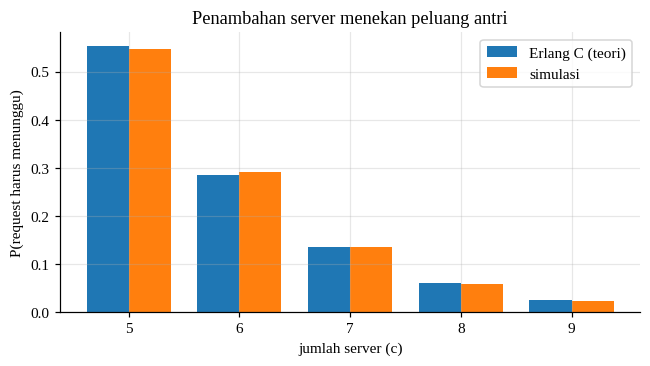

In [51]:
fig, ax = plt.subplots(figsize=(6.8, 3.3))
lebar = 0.38
ax.bar(tabel.c - lebar / 2, tabel["P(tunggu) teori"], lebar, label="Erlang C (teori)")
ax.bar(tabel.c + lebar / 2, tabel["P(tunggu) sim"], lebar, label="simulasi")
ax.set(xlabel="jumlah server (c)", ylabel="P(request harus menunggu)",
       title="Penambahan server menekan peluang antri")
ax.legend()
plt.show()

**Interpretasi.** Pada c = 5 (ρ = 0,8) peluang menunggu 0,5541 menurut Erlang C dan 0,5507 menurut simulasi. Dengan c = 6 peluangnya turun menjadi 0,2848 dan P(Wq > 0,1 s) = 0,0385 (simulasi 0,0398), yang sudah di bawah batas 5%. Jadi jumlah *server* minimal adalah 6. Penambahan ke c = 7, 8, dan 9 menurunkan peluang antri menjadi 0,1351; 0,0590; dan 0,0238, dengan simulasi yang cocok pada setiap baris.

Hasil menarik lain: satu *server* yang lima kali lebih cepat (μ = 50) memberi rata-rata waktu di sistem 0,1 detik, sedangkan lima *server* berkecepatan 10 hanya mencapai 0,1554 detik walaupun kapasitas totalnya sama. Hal ini terjadi karena pada satu *server* cepat tidak ada kapasitas yang menganggur sementara pekerjaan lain menunggu. Tentu saja model ini mengabaikan keuntungan redundansi bila satu *server* mati.

**Kesimpulan kasus.** Rumus Erlang C dan simulasi saling memverifikasi, dan memberi dasar kuantitatif untuk menentukan jumlah *server*.

# Bagian E - Rekap Verifikasi dan Panduan Memilih Distribusi

In [ ]:
rekap = pd.DataFrame(REKAP)
nilai = rekap[["analitik", "pustaka", "simulasi"]].astype(float)
rekap["selisih"] = (nilai.analitik - nilai.pustaka).abs()
rekap["z-sim"] = (nilai.simulasi - nilai.analitik) / rekap.se.astype(float)
# cocok: rumus = pustaka (toleransi 1e-3) dan simulasi dalam 3 galat baku Monte Carlo
rekap["status"] = np.where((rekap["selisih"] < 1e-3)
                           & ~(rekap["z-sim"].abs() > 3), "cocok", "periksa")
print(rekap.drop(columns="se").round(5).to_string(index=False))
print("\nJumlah besaran diperiksa :", len(rekap))
print("Berstatus cocok          :", (rekap.status == "cocok").sum())

kasus                          besaran  analitik  pustaka  simulasi  selisih    z-sim status
   P1             P(tabrakan), n = 300   0.49611  0.49611   0.49230  0.00000 -1.07828  cocok
   P2               P(malware | alarm)   0.32646  0.32646   0.32590  0.00000 -0.28875  cocok
   P3             P(spam | email ke-3)   0.80168  0.80168       NaN  0.00000      NaN  cocok
   P4                 keandalan sistem   0.99136  0.99136   0.99150  0.00000  1.08078  cocok
   P5                      pi(Beranda)   0.23369  0.23369   0.23320  0.00000 -0.71931  cocok
   P6 P(rata-rata 30 request > 230 ms)   0.19935  0.19935   0.20355  0.00000  1.48657  cocok
   P7   P(password 8 karakter lengkap)   0.73123  0.73123   0.73172  0.00000  1.12386  cocok
   D1                        P(X <= 2)   0.78795  0.78795   0.78716  0.00000 -1.04907  cocok
   D2                        P(X <= 3)   0.97300  0.97300   0.97308  0.00000  0.49357  cocok
   D3                       P(T <= 20)   0.59510  0.59510   0.59517  0

In [ ]:
panduan = pd.DataFrame([
    ("Hitung kegagalan dari n percobaan tetap", "Binomial", "stats.binom", "paket hilang"),
    ("Percobaan ke berapa sukses pertama", "Geometrik", "stats.geom", "retry koneksi"),
    ("Percobaan sampai sukses ke-r", "Binomial negatif", "stats.nbinom", "uji sampai r bug"),
    ("Kejadian acak per satuan waktu", "Poisson", "stats.poisson", "request per detik"),
    ("Ambil sampel tanpa pengembalian", "Hipergeometrik", "stats.hypergeom", "audit test case"),
    ("Banyak kategori sekaligus", "Multinomial", "stats.multinomial", "pembagian beban server"),
    ("Semua nilai sama mungkin (diskrit)", "Seragam diskrit", "stats.randint", "hash bucket"),
    ("Semua nilai sama mungkin (kontinu)", "Uniform", "stats.uniform", "jitter, backoff acak"),
    ("Waktu tunggu tanpa memori", "Eksponensial", "stats.expon", "selang antar-request"),
    ("Waktu sampai kejadian ke-k", "Gamma / Erlang", "stats.gamma", "waktu k request"),
    ("Umur dengan laju gagal berubah", "Weibull", "stats.weibull_min", "keandalan disk"),
    ("Hasil jumlah banyak faktor kecil", "Normal", "stats.norm", "latensi, galat ukur"),
    ("Data positif berekor panjang", "Lognormal", "stats.lognorm", "ukuran file"),
    ("Peluang yang tidak diketahui (0-1)", "Beta", "stats.beta", "tingkat konversi"),
    ("Sampel kecil, sigma tak diketahui", "t Student", "stats.t", "benchmark algoritma"),
    ("Selang kepercayaan untuk varians", "Chi-kuadrat", "stats.chi2", "kestabilan waktu"),
], columns=["Situasi", "Distribusi", "Fungsi scipy", "Contoh di Informatika"])
print(panduan.to_string(index=False))

                                Situasi       Distribusi      Fungsi scipy  Contoh di Informatika
Hitung kegagalan dari n percobaan tetap         Binomial       stats.binom           paket hilang
     Percobaan ke berapa sukses pertama        Geometrik        stats.geom          retry koneksi
           Percobaan sampai sukses ke-r Binomial negatif      stats.nbinom       uji sampai r bug
         Kejadian acak per satuan waktu          Poisson     stats.poisson      request per detik
        Ambil sampel tanpa pengembalian   Hipergeometrik   stats.hypergeom        audit test case
              Banyak kategori sekaligus      Multinomial stats.multinomial pembagian beban server
     Semua nilai sama mungkin (diskrit)  Seragam diskrit     stats.randint            hash bucket
     Semua nilai sama mungkin (kontinu)          Uniform     stats.uniform   jitter, backoff acak
              Waktu tunggu tanpa memori     Eksponensial       stats.expon   selang antar-request
             Waktu s

## Kesimpulan

- Dua puluh empat kasus berhasil diimplementasikan dan dijalankan tanpa galat. Untuk setiap besaran kunci, nilai dari rumus, dari pustaka Python, dan dari simulasi atau enumerasi saling bersesuaian; pada 23 besaran yang memiliki simulasi (semua kecuali P3), hasil simulasi selalu berada dalam tiga galat baku dari nilai analitiknya.

- Pada permasalahan probabilitas, beberapa hasil bertentangan dengan intuisi dan hanya bisa diyakini setelah dihitung: tabrakan ID sudah 50% pada sekitar 302 pengguna (P1), alarm detektor dengan sensitivitas 95% ternyata hanya benar sekitar sepertiga kali (P2), dan aturan kompleksitas *password* hanya mengurangi ruang tebakan sekitar 27% (P7).

- Pada distribusi diskrit dan kontinu, kecocokan model ditentukan oleh asumsi: Poisson mengasumsikan kejadian independen dengan laju tetap, eksponensial tidak berpemori, sedangkan Weibull dan lognormal menangkap penuaan dan ekor panjang yang tidak bisa dijelaskan model sederhana. Beberapa temuan praktis, misalnya anggaran pengujian harus dihitung dari kuantil (D3), *backoff* berbahaya bila peluang sukses di bawah 0,5 (D2), dan rata-rata dapat menyesatkan pada sebaran berekor panjang (K6).

- Studi kasus terpadu memperlihatkan bahwa pemahaman distribusi dapat langsung diterjemahkan menjadi keputusan teknik: kapasitas minimal 13,99 *request* per detik untuk antrian tunggal (T1) dan 6 *server* untuk beban 40 *request* per detik (T2).

- Keterbatasan: data pada kasus P3, K6, dan K8 dibangkitkan atau disusun sendiri sehingga tidak mewakili data nyata; model antrian mengasumsikan kedatangan Poisson dan layanan eksponensial; dan parameter pada semua skenario adalah contoh. Langkah lanjutan yang wajar adalah mencoba metode yang sama pada data *log* nyata.